# Análisis Predictivo del Mercado Hipotecario Español
**TFM — Ciencia de Datos Aplicada al Sector Inmobiliario**

Este notebook realiza el análisis completo del mercado hipotecario español mediante:
- Corrección de **data leakage** mediante lags temporales
- Modelos de **Machine Learning** (Random Forest, XGBoost, LASSO)
- Modelos de **Series Temporales** (SARIMAX, VAR, Cointegración de Johansen)
- **Mapas geoespaciales** de accesibilidad y tensión del mercado
- **Proyección 2026-2030** con macro dinámica BCE/FMI

# Estado del Arte: Marco Teórico y Bibliografía

## Justificación académica de la hibridación entre Econometría y Machine Learning

La metodología aplicada en este trabajo de fin de máster se encuadra dentro de lo que la literatura académica contemporánea denomina modelos híbridos de predicción (*Hybrid Forecasting Models*). Esta corriente representa la vanguardia en el análisis de series temporales, fundamentando la validez de combinar el rigor estructural y causal de la econometría clásica con la flexibilidad y capacidad predictiva del aprendizaje automático.

---

## Fuentes fundamentales de la investigación

### Las competiciones M de Makridakis y la superioridad de los modelos híbridos

Los resultados de la **M4 Competition (2018)**, organizada por Spyros Makridakis, constituyen la evidencia empírica principal que sustenta este trabajo. En dicho certamen se demostró que los modelos que combinan estadística tradicional con algoritmos de Machine Learning minimizan el error de predicción de forma más eficiente que cualquier método aplicado de forma aislada.

Basándome en estos hallazgos, sostengo en esta investigación que la combinación de métodos estadísticos clásicos con algoritmos de Machine Learning permite reducir el error en la previsión del mercado hipotecario español mejor que cualquier método convencional de manera independiente.

### La integración de nuevas técnicas según Hal Varian

Una referencia fundamental en este estudio es el trabajo de **Varian (2014), *Big Data: New Tricks for Econometrics***. El autor expone que las herramientas tradicionales de la econometría son necesarias para establecer causalidad y equilibrio mediante técnicas como la cointegración, pero que el Machine Learning ofrece una potencia superior en la selección de variables e identificación de patrones en entornos con múltiples predictores.

### La adopción institucional de la Inteligencia Artificial explicable (XAI)

La adopción de estas técnicas por parte de instituciones como el Banco de Inglaterra y el Banco Central Europeo refuerza la base de este trabajo. En particular, tomo como referencia el trabajo de **Chakraborty y Joseph (2017), *Machine Learning at Central Banks***, publicado por el Banco de Inglaterra.

---

## Síntesis del Estado de la Cuestión

| Bloque Metodológico | Referencias Base | Aportación a este Trabajo |
| :--- | :--- | :--- |
| **Modelos Clásicos** | VAR / VECM | Se consideran fundamentales para asegurar la coherencia económica y el equilibrio a largo plazo mediante el test de cointegración de Johansen. |
| **Modelos de Aprendizaje** | Random Forest / XGBoost | Se utilizan por su alta precisión predictiva en datos heterogéneos. |
| **Enfoque Híbrido** | Makridakis (2018) y Varian (2014) | Síntesis final: cointegración para estabilidad + Random Forest con SHAP para precisión explicativa. |

## 1. Importaciones y Configuración
Cargamos todas las librerías necesarias para el análisis.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import geopandas as gpd
import unicodedata
from difflib import get_close_matches
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import scipy.stats as stats
import xgboost as xgb
import shap
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LassoCV, lasso_path
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from sklearn.model_selection import learning_curve
import warnings
warnings.filterwarnings('ignore')
print("✅ Librerías cargadas correctamente.")

✅ Librerías cargadas correctamente.


## 2. Carga del Dataset
Cargamos el dataset principal `dataset_final_tfm.csv` con estructura de panel temporal (52 provincias × trimestres desde 2005).

In [32]:
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
df = df.sort_values(['Provincia', 'Trimestre']).reset_index(drop=True)
print(f"Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Provincias: {df['Provincia'].nunique()} | Trimestres: {df['Trimestre'].nunique()}")
print(f"Rango: {df['Trimestre'].min().date()} → {df['Trimestre'].max().date()}")
df.tail()

Dataset cargado: 4,368 filas × 16 columnas
Provincias: 52 | Trimestres: 84
Rango: 2005-01-01 → 2025-10-01


,Provincia,Trimestre,Precio_m2,Euribor,tasa_ahorro,Spread_Hipotecas,Hipotecas_Total,Poblacion,Edad_Media,PIB_pc,Indice_Mano_Obra,Indice_Materiales,IPC,Tasa_Paro,Pob_Ext,Transmisiones_Total
4363,Ávila,2024-10-01,989.168120,2.547879,17.1,0.618788,492.0,160463.0,48.46,24928.0,470.476667,2905.295238,2.133333,9.47,16969.0,3805.0
4364,Ávila,2025-01-01,1021.998740,2.445531,4.9,0.481135,414.0,160738.0,48.51,NaN,473.823333,2976.490476,2.533333,8.35,17853.0,3630.0
4365,Ávila,2025-04-01,1019.785520,2.101523,20.4,0.695144,435.0,160738.0,48.51,NaN,NaN,NaN,2.100000,11.89,17853.0,11076.0
4366,Ávila,2025-07-01,1037.656570,2.120970,4.6,0.602364,401.0,160738.0,48.51,NaN,NaN,NaN,2.766667,7.08,17853.0,12816.0
4367,Ávila,2025-10-01,1047.329133,2.224030,NaN,0.449303,555.0,160738.0,48.51,NaN,NaN,NaN,2.966667,8.20,17853.0,2610.0


## 3. Corrección de Data Leakage — Creación de Lags Temporales

> **ADVERTENCIA:** `dataset_final_tfm.csv` tiene estructura de panel temporal (52 provincias × trimestres).
> Las siguientes columnas tienen **data leakage** porque son contemporáneas al target `Hipotecas_Total`:
> `Precio_m2`, `Transmisiones_Total`, `Spread_Hipotecas`, `Tasa_Paro`, `IPC`, `Indice_Mano_Obra`, `Indice_Materiales`.

**Solución:** Se crean columnas `_lag1` (trimestre anterior) y `_lag4` (año anterior) para todas las variables problemáticas, agrupando por provincia.

In [33]:
# Relleno de nulos antes de crear lags
cols_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc',
             'Pob_Ext', 'Transmisiones_Total', 'Edad_Media']
for col in cols_fill:
    if col in df.columns:
        df[col] = df.groupby('Provincia')[col].transform(lambda x: x.ffill().bfill())

# Creación de lags
lag_cols = ['Precio_m2', 'Transmisiones_Total', 'Spread_Hipotecas',
            'Tasa_Paro', 'IPC', 'Indice_Mano_Obra', 'Indice_Materiales',
            'Hipotecas_Total', 'Pob_Ext', 'Poblacion', 'PIB_pc', 'tasa_ahorro', 'Edad_Media']

for col in lag_cols:
    if col in df.columns:
        df[f'{col}_lag1'] = df.groupby('Provincia')[col].shift(1)
        df[f'{col}_lag4'] = df.groupby('Provincia')[col].shift(4)

df['Euribor_ma4'] = df.groupby('Provincia')['Euribor'].transform(
    lambda x: x.shift(1).rolling(4).mean())
df['Precio_m2_pct'] = df.groupby('Provincia')['Precio_m2'].pct_change(1)

df = df.dropna().reset_index(drop=True)
print(f"Lags creados. Dataset listo: {df.shape[0]:,} filas, {df.shape[1]} columnas")

# Features estándar para modelos ML (sin inercia)
FEATURES_BASE = ['Euribor'] + [f'{col}_lag1' for col in lag_cols if f'{col}_lag1' in df.columns]

# Features con inercia (Random Forest final)
_FEATURES_CON = [
    'Hipotecas_Total_lag1', 'Hipotecas_Total_lag4',
    'Precio_m2_lag1', 'Euribor', 'tasa_ahorro_lag1', 'Spread_Hipotecas_lag1',
    'Poblacion_lag1', 'Edad_Media_lag1', 'Pob_Ext_lag1', 'Transmisiones_Total_lag1',
    'Indice_Mano_Obra_lag1', 'Indice_Materiales_lag1', 'IPC_lag1', 'Tasa_Paro_lag1', 'PIB_pc_lag1'
]
_FEATURES_CON = [f for f in _FEATURES_CON if f in df.columns]
_DF_BASE = df.copy()
print(f"Features base: {len(FEATURES_BASE)} | Features con inercia: {len(_FEATURES_CON)}")

Lags creados. Dataset listo: 4,160 filas, 44 columnas
Features base: 14 | Features con inercia: 15


## 4. Análisis Exploratorio — Mapas Geoespaciales

### 4.1 Mapa de Tensión del Mercado Inmobiliario
Visualizamos el precio del m² por provincia en el último trimestre disponible como indicador de tensión del mercado.

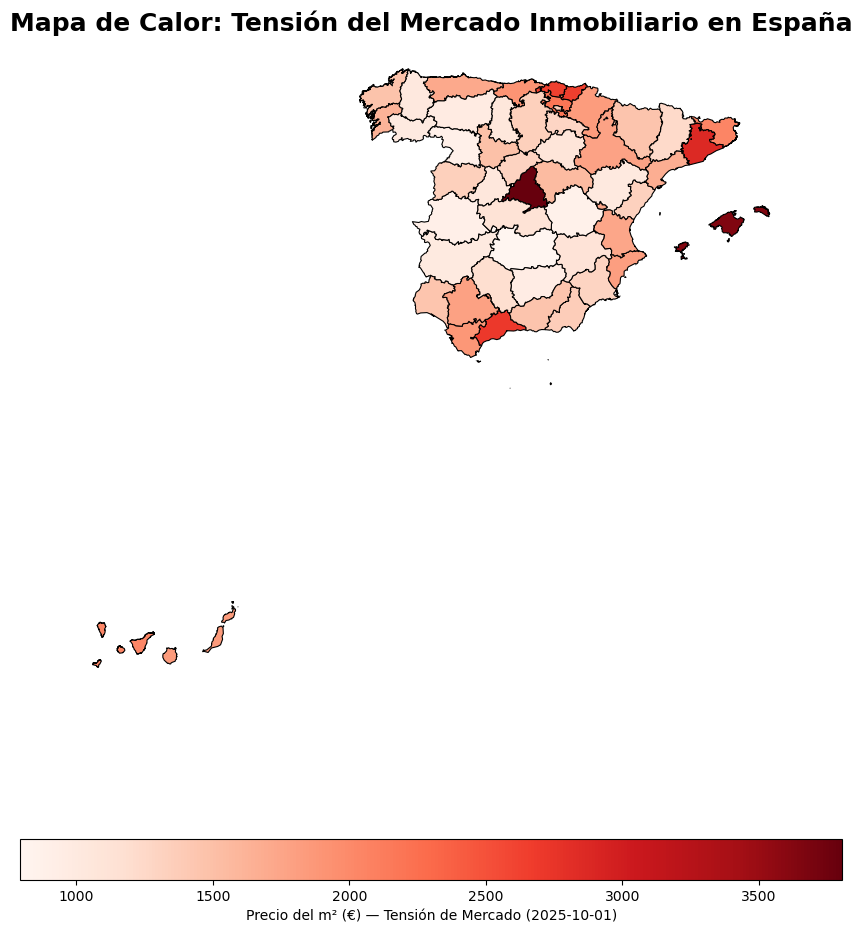

In [34]:
def clean_text_map(text):
    if pd.isna(text): return ""
    s = str(text).lower().strip()
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

DICCIONARIO_MAPA = {
    'illes balears': 'islas baleares', 'alacant/alicante': 'alicante',
    'castello/castellon': 'castellon', 'valencia/valencia': 'valencia',
    'araba/alava': 'alava', 'bizkaia/vizcaya': 'vizcaya',
    'gipuzkoa/guipuzcoa': 'guipuzcoa', 'madrid': 'comunidad de madrid',
    'murcia': 'region de murcia', 'asturias': 'principado de asturias',
    'navarra': 'comunidad foral de navarra', 'la coruna': 'a coruna',
    'las palmas': 'las palmas', 'santa cruz de tenerife': 'santa cruz de tenerife'
}

url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson"
gdf = gpd.read_file(url_geojson)
gdf['name_clean'] = gdf['name'].apply(clean_text_map).replace(DICCIONARIO_MAPA)

ultimo_trimestre = df['Trimestre'].max()
df_reciente = df[df['Trimestre'] == ultimo_trimestre].copy()
df_reciente['Prov_clean'] = df_reciente['Provincia'].apply(clean_text_map)
merged = gdf.merge(df_reciente, left_on='name_clean', right_on='Prov_clean', how='left')

fig, ax = plt.subplots(1, 1, figsize=(14, 10))
merged.plot(column='Precio_m2', cmap='Reds', linewidth=0.8, ax=ax, edgecolor='black',
            legend=True,
            legend_kwds={'label': f"Precio del m² (€) — Tensión de Mercado ({ultimo_trimestre.date()})",
                         'shrink': 0.6, 'orientation': 'horizontal'},
            missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})
plt.title("Mapa de Calor: Tensión del Mercado Inmobiliario en España", fontsize=18, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

### 4.2 Mapa de Accesibilidad Hipotecaria
Calculamos el **Índice de Accesibilidad** = (PIB per cápita × tasa de empleo) / precio m².

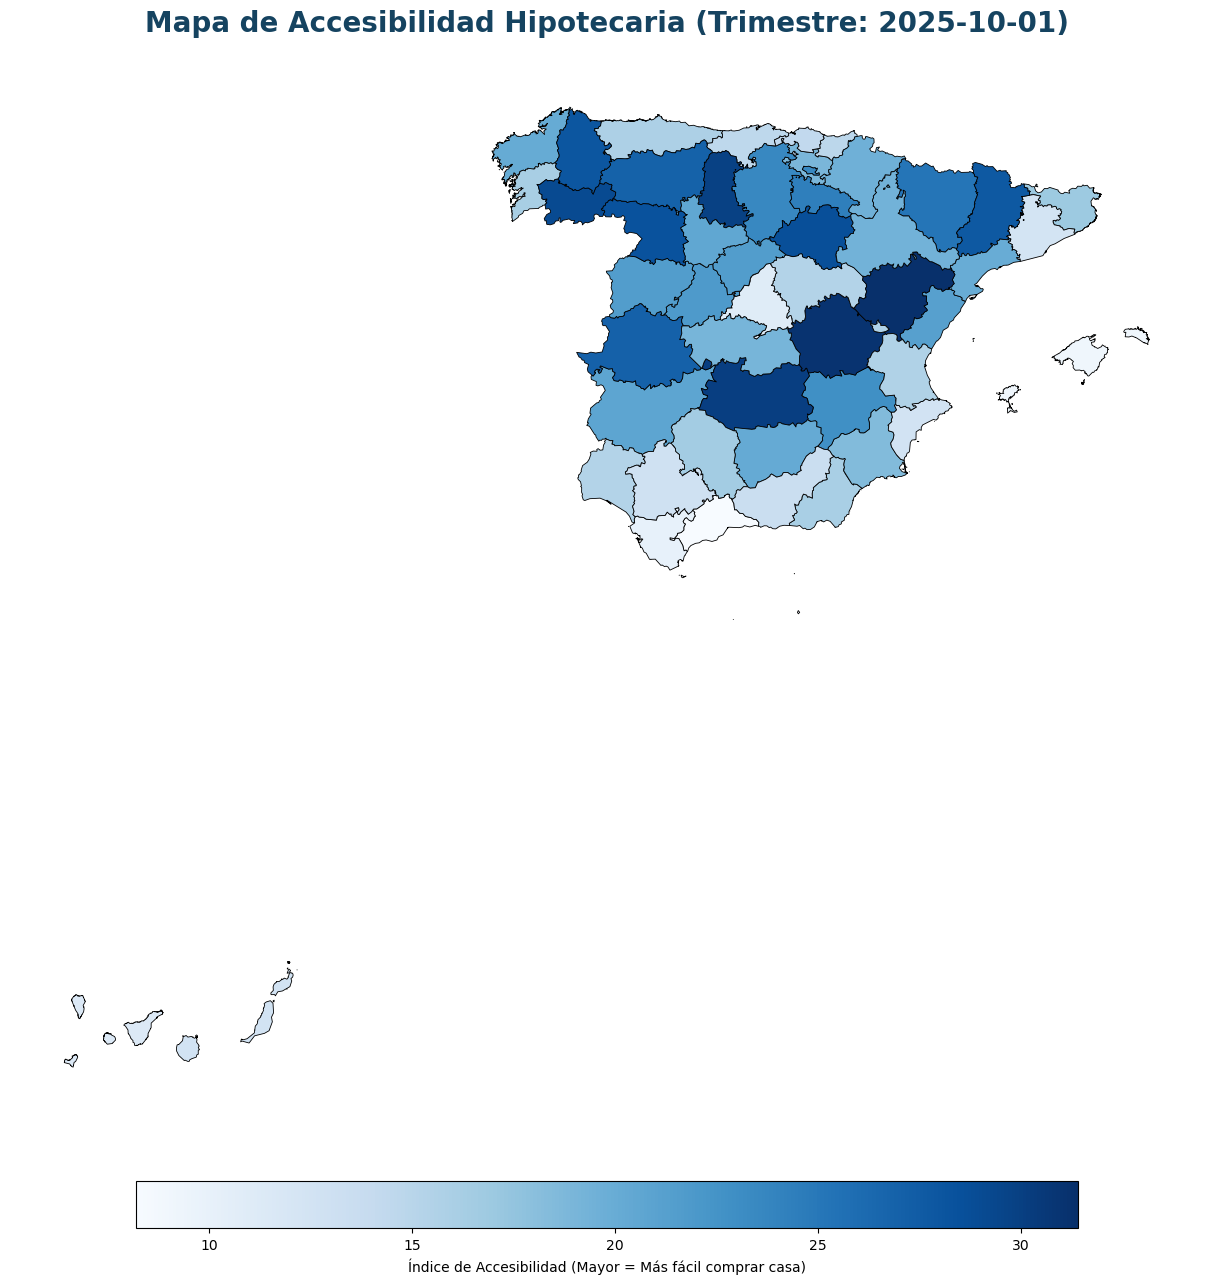

✅ Mapa renderizado.


In [35]:
df['Accesibilidad'] = (df['PIB_pc'] * (1 - df['Tasa_Paro']/100)) / df['Precio_m2']
df_map = df[df['Trimestre'] == ultimo_trimestre].copy()
df_map['Provincia_Clean'] = df_map['Provincia'].apply(clean_text_map)
merged2 = gdf.merge(df_map, left_on='name_clean', right_on='Provincia_Clean', how='left')

fig, ax = plt.subplots(1, 1, figsize=(16, 14))
ax.set_facecolor('white'); ax.axis('off')
merged2.plot(column='Accesibilidad', cmap='Blues', linewidth=0.6, ax=ax, edgecolor='black',
             legend=True,
             legend_kwds={'label': "Índice de Accesibilidad (Mayor = Más fácil comprar casa)",
                          'orientation': "horizontal", 'shrink': 0.6, 'pad': 0.05},
             missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})
plt.title(f"Mapa de Accesibilidad Hipotecaria (Trimestre: {ultimo_trimestre.date()})",
          fontsize=20, fontweight='bold', color='#154360', pad=20)
plt.tight_layout()
plt.show()
print("✅ Mapa renderizado.")

## 5. Análisis Econométrico

### 5.1 ACF y PACF de las Hipotecas Nacionales
Antes de los tests formales, la ACF y la PACF permiten identificar visualmente el orden de integración y los órdenes AR/MA apropiados.

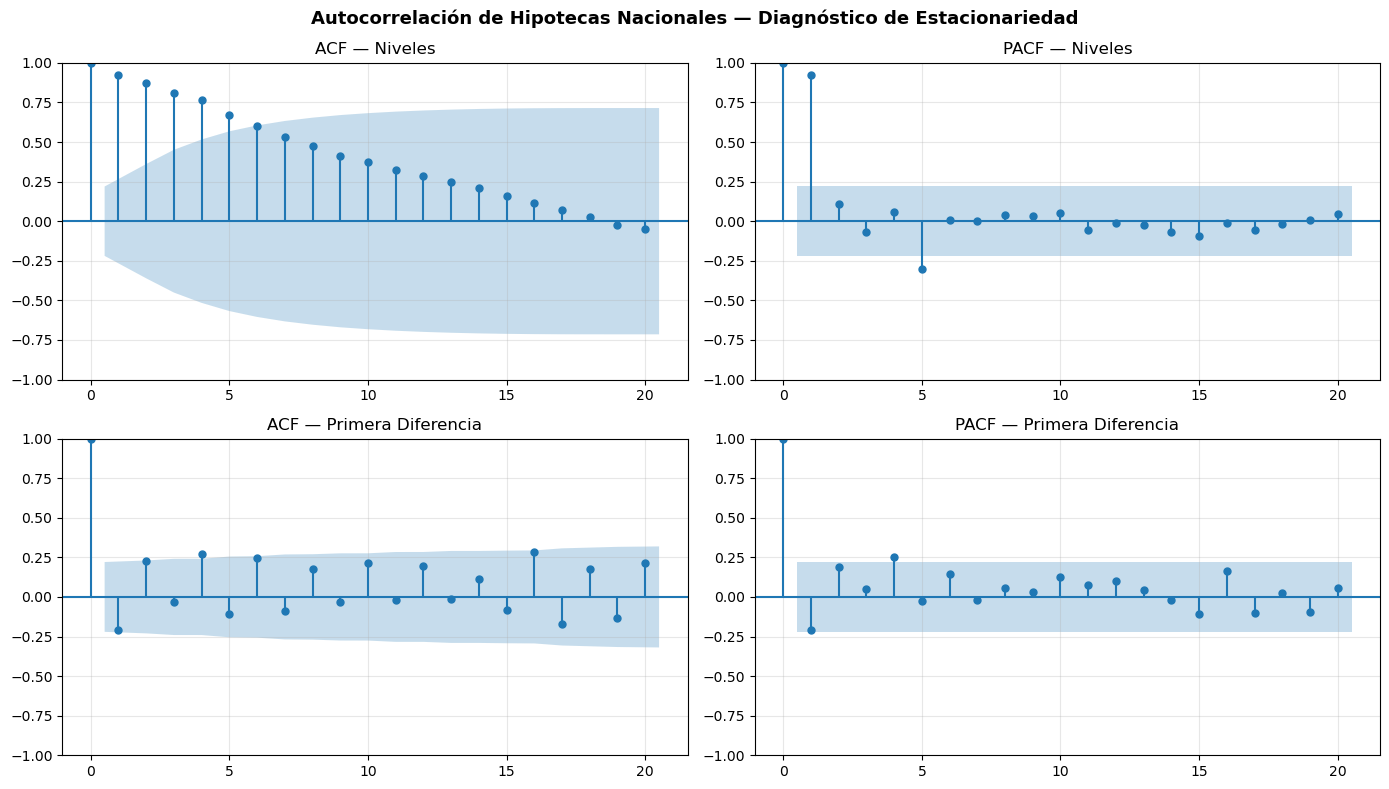

In [36]:
df_acf = df.groupby('Trimestre')['Hipotecas_Total'].sum().sort_index()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Autocorrelación de Hipotecas Nacionales — Diagnóstico de Estacionariedad",
             fontsize=13, fontweight='bold')

plot_acf(df_acf.dropna(),  lags=20, ax=axes[0,0], title="ACF — Niveles")
plot_pacf(df_acf.dropna(), lags=20, ax=axes[0,1], title="PACF — Niveles", method='ywm')
df_diff = df_acf.diff().dropna()
plot_acf(df_diff,  lags=20, ax=axes[1,0], title="ACF — Primera Diferencia")
plot_pacf(df_diff, lags=20, ax=axes[1,1], title="PACF — Primera Diferencia", method='ywm')

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

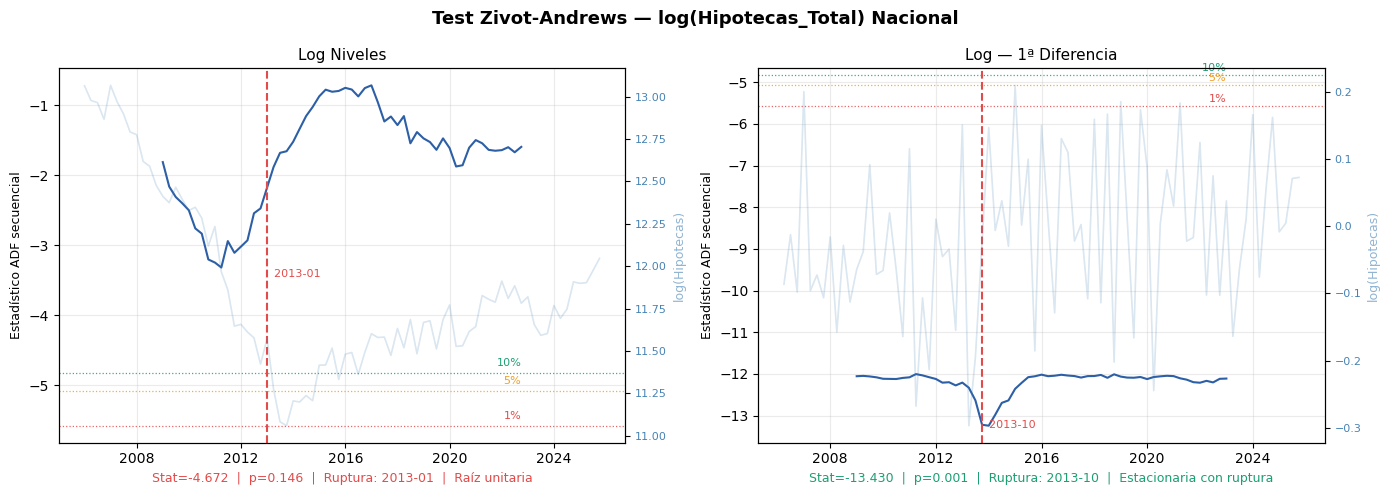

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import zivot_andrews, adfuller

df_log  = np.log(df.groupby('Trimestre')['Hipotecas_Total'].sum().sort_index())
df_diff = df_log.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Test Zivot-Andrews — log(Hipotecas_Total) Nacional",
             fontsize=13, fontweight='bold')

for ax, (serie, nombre) in zip(axes, [(df_log,  "Log Niveles"),
                                       (df_diff, "Log — 1ª Diferencia")]):

    za      = zivot_andrews(serie, maxlag=8, regression='ct', autolag='AIC')
    stat    = float(za[0])
    crit    = za[2]          # dict con '1%', '5%', '10%'
    baselag = int(za[3])
    bpidx   = int(za[4])     # índice de ruptura — era [4], no [2]
    bp_date = serie.index[bpidx]

    # --- Secuencia del estadístico ADF en cada posible punto de ruptura ---
    trim      = int(0.15 * len(serie))
    stats_seq = []
    dates_seq = []

    for t in range(trim, len(serie) - trim):
        dummy     = np.zeros(len(serie))
        dummy[t:] = 1
        X = sm.add_constant(
                pd.DataFrame({'trend': np.arange(len(serie)),
                              'dummy': dummy},
                             index=serie.index))
        resid = sm.OLS(serie.values, X).fit().resid
        try:
            s = adfuller(resid, maxlag=baselag, autolag=None)[0]
            stats_seq.append(s)
            dates_seq.append(serie.index[t])
        except Exception:
            continue

    # --- Serie original en eje secundario ---
    ax2 = ax.twinx()
    ax2.plot(serie.index, serie.values, color='steelblue',
             alpha=0.2, linewidth=1.2, zorder=1)
    ax2.set_ylabel('log(Hipotecas)', fontsize=9, color='steelblue', alpha=0.6)
    ax2.tick_params(axis='y', labelcolor='steelblue', labelsize=8)

    # --- Estadístico secuencial ---
    ax.plot(dates_seq, stats_seq, color='#2d5fa6', linewidth=1.5, zorder=2)
    ax.axvline(bp_date, color='#E24B4A', linewidth=1.5, linestyle='--', zorder=3)
    ax.text(bp_date, ax.get_ylim()[0] if ax.get_ylim()[0] != 0 else -8,
            f"  {str(bp_date)[:7]}", color='#E24B4A', fontsize=8)

    # --- Valores críticos ---
    colors_crit = {'1%': '#E24B4A', '5%': '#EF9F27', '10%': '#1D9E75'}
    for nivel, val in crit.items():
        ax.axhline(val, color=colors_crit.get(nivel, 'gray'),
                   linewidth=0.9, linestyle=':', alpha=0.85)
        ax.text(dates_seq[-1], val + 0.1, nivel,
                fontsize=8, color=colors_crit.get(nivel, 'gray'), ha='right')

    # --- Veredicto ---
    rechaza = stat < crit.get('5%', -5.07)
    verdict = "Estacionaria con ruptura" if rechaza else "Raíz unitaria"
    color_v = '#1D9E75' if rechaza else '#E24B4A'

    ax.set_title(nombre, fontsize=11)
    ax.set_xlabel(
        f"Stat={stat:.3f}  |  p={float(za[1]):.3f}  |  Ruptura: {str(bp_date)[:7]}  |  {verdict}",
        fontsize=9, color=color_v)
    ax.set_ylabel("Estadístico ADF secuencial", fontsize=9)
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

### 5.2 Test de Raíz Unitaria (ADF)
Verificación formal de estacionariedad de las series.

In [38]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller

df_nac_adf = df.groupby('Trimestre').agg({
    'Hipotecas_Total':    'sum',
    'Transmisiones_Total':'sum',
    'Poblacion':          'sum',
    'Euribor':            'mean',
    'Precio_m2':          'mean',
    'Tasa_Paro':          'mean',
    'PIB_pc':             'mean',
    'IPC':                'mean',
    'tasa_ahorro':        'mean',
    'Spread_Hipotecas':   'mean',
    'Edad_Media':         'mean',
    'Indice_Mano_Obra':   'mean',
    'Indice_Materiales':  'mean'
}).sort_index()

# ── Clasificación A/B según tus apuntes ─────────────────────────
# A → log(Yt): variables de precio, cantidad, índice — se habla de tasas de crecimiento
# B → Xt:      variables que ya son tasas o tipos — NO se aplica log
vars_A = ['Hipotecas_Total', 'Transmisiones_Total', 'Poblacion',
          'Precio_m2', 'PIB_pc', 'Indice_Mano_Obra', 'Indice_Materiales']

vars_B = ['Euribor', 'Tasa_Paro', 'IPC', 'tasa_ahorro',
          'Spread_Hipotecas', 'Edad_Media']

def test_adf(series, maxlag=8):
    """Devuelve p-valor con selección automática de lags por AIC."""
    return adfuller(series.dropna(), maxlag=maxlag, autolag='AIC')[1]

resultados = []

for col in sorted(df_nac_adf.columns):
    series_raw = df_nac_adf[col].dropna()
    if len(series_raw) < 12:
        continue

    if col in vars_A:
        tipo   = 'A — log'
        series = np.log(series_raw)           # test sobre log(Yt)
        diff1  = series.diff().dropna()       # log(Yt) - log(Yt-1)
        diff2  = diff1.diff().dropna()        # segunda diferencia
        label_nivel = 'log(Y)'
        label_d1    = 'Δlog(Y)'
        label_d2    = 'Δ²log(Y)'
    else:
        tipo   = 'B — nivel'
        series = series_raw                   # test sobre Xt directamente
        diff1  = series.diff().dropna()       # Xt - Xt-1
        diff2  = diff1.diff().dropna()
        label_nivel = 'Y'
        label_d1    = 'ΔY'
        label_d2    = 'Δ²Y'

    p0 = test_adf(series)
    p1 = test_adf(diff1) if len(diff1) >= 10 else 1.0
    p2 = test_adf(diff2) if len(diff2) >= 10 else 1.0

    if   p0 < 0.05: orden = f"I(0) — estacionaria en {label_nivel}"
    elif p1 < 0.05: orden = f"I(1) — estacionaria en {label_d1}"
    elif p2 < 0.05: orden = f"I(2) — estacionaria en {label_d2}"
    else:           orden = "I(2)+ — revisar con Zivot-Andrews"

    resultados.append({
        'Variable':      col,
        'Tipo':          tipo,
        'p nivel':       f"{p0:.4f}",
        'p 1ª dif':      f"{p1:.4f}",
        'p 2ª dif':      f"{p2:.4f}",
        'Orden':         orden
    })

df_adf = pd.DataFrame(resultados)
print(df_adf.to_string(index=False))

           Variable      Tipo p nivel p 1ª dif p 2ª dif                             Orden
         Edad_Media B — nivel  0.8016   0.2976   0.0000        I(2) — estacionaria en Δ²Y
            Euribor B — nivel  0.2539   0.0001   0.0000         I(1) — estacionaria en ΔY
    Hipotecas_Total   A — log  0.1364   0.0000   0.0000    I(1) — estacionaria en Δlog(Y)
                IPC B — nivel  0.0319   0.0002   0.0000          I(0) — estacionaria en Y
   Indice_Mano_Obra   A — log  0.9606   0.0209   0.0006    I(1) — estacionaria en Δlog(Y)
  Indice_Materiales   A — log  0.7563   0.0000   0.0000    I(1) — estacionaria en Δlog(Y)
             PIB_pc   A — log  0.9776   0.0000   0.0000    I(1) — estacionaria en Δlog(Y)
          Poblacion   A — log  0.7518   0.3675   0.0000   I(2) — estacionaria en Δ²log(Y)
          Precio_m2   A — log  0.3006   0.7777   0.0577 I(2)+ — revisar con Zivot-Andrews
   Spread_Hipotecas B — nivel  0.5447   0.0000   0.0000         I(1) — estacionaria en ΔY
          

In [39]:
from statsmodels.tsa.stattools import zivot_andrews

serie_paro = df_nac_adf['Tasa_Paro'].dropna()
resultado  = zivot_andrews(serie_paro, maxlag=4, autolag='t-stat')
print(f"ZA Statistic:         {resultado[0]:.4f}")
print(f"p-value:              {resultado[1]:.4f}")
print(f"Ruptura detectada en: {serie_paro.index[resultado[4]]}")

ZA Statistic:         -4.8292
p-value:              0.0479
Ruptura detectada en: 2011-04-01 00:00:00


In [40]:
# Zivot-Andrews para log(Precio_m2)
serie_za = np.log(df_nac_adf['Precio_m2'].dropna())

for serie, etiqueta in [(serie_za,              'log(Precio_m2)'),
                         (serie_za.diff().dropna(), 'Δlog(Precio_m2)')]:
    za      = zivot_andrews(serie, maxlag=8, regression='ct', autolag='AIC')
    stat    = float(za[0])
    crit_5  = za[2].get('5%', -5.08)
    bpidx   = int(za[4])
    bp_date = serie.index[bpidx]
    rechaza = stat < crit_5
    print(f"{etiqueta:20s} | stat={stat:.3f} | ruptura={str(bp_date)[:7]} | {'estacionaria con ruptura' if rechaza else 'no rechaza raíz unitaria'}")

log(Precio_m2)       | stat=-2.902 | ruptura=2012-10 | no rechaza raíz unitaria
Δlog(Precio_m2)      | stat=-3.556 | ruptura=2011-07 | no rechaza raíz unitaria


### 5.3 Test de Cointegración de Johansen
Verificamos si existen relaciones de largo plazo entre las variables del mercado hipotecario.

In [41]:
df_johansen = pd.DataFrame()
df_johansen['Log_Hipotecas']  = np.log(df_nac_adf['Hipotecas_Total'])
df_johansen['Log_PIB_pc']     = np.log(df_nac_adf['PIB_pc'])
df_johansen['Log_Precio_m2']  = np.log(df_nac_adf['Precio_m2'])
df_johansen['Log_Materiales'] = np.log(df_nac_adf['Indice_Materiales'])
df_johansen['Euribor']        = df_nac_adf['Euribor']
df_johansen['Spread']         = df_nac_adf['Spread_Hipotecas']
df_johansen = df_johansen.dropna()

res_joh = coint_johansen(df_johansen, det_order=0, k_ar_diff=2)

output_joh = []
for i in range(len(res_joh.lr1)):
    traza = res_joh.lr1[i]
    crit  = res_joh.cvt[i, 1]
    decision = "SÍ Existe Cointegración" if traza > crit else "No hay evidencia suficiente"
    output_joh.append({'H0 (Rango)': f"r <= {i}", 'Estadístico Traza': f"{traza:.2f}",
                       'Valor Crítico 95%': f"{crit:.2f}", 'Conclusión': decision})

print("--- TEST DE JOHANSEN (Traza) ---")
print(pd.DataFrame(output_joh).to_string(index=False))

output_mv = []
for i in range(len(res_joh.lr2)):
    mv   = res_joh.lr2[i]
    crit = res_joh.cvm[i, 1]
    decision = "SÍ Existe Cointegración" if mv > crit else "No hay evidencia suficiente"
    output_mv.append({'H0 (Rango)': f"r <= {i}", 'Estadístico Máx. Autovalor': f"{mv:.2f}",
                      'Valor Crítico 95%': f"{crit:.2f}", 'Conclusión': decision})

print("\n--- TEST DE JOHANSEN (Máx. Autovalor) ---")
print(pd.DataFrame(output_mv).to_string(index=False))

--- TEST DE JOHANSEN (Traza) ---
H0 (Rango) Estadístico Traza Valor Crítico 95%                  Conclusión
    r <= 0            122.43             95.75     SÍ Existe Cointegración
    r <= 1             84.47             69.82     SÍ Existe Cointegración
    r <= 2             52.38             47.85     SÍ Existe Cointegración
    r <= 3             32.62             29.80     SÍ Existe Cointegración
    r <= 4             15.68             15.49     SÍ Existe Cointegración
    r <= 5              0.16              3.84 No hay evidencia suficiente

--- TEST DE JOHANSEN (Máx. Autovalor) ---
H0 (Rango) Estadístico Máx. Autovalor Valor Crítico 95%                  Conclusión
    r <= 0                      37.96             40.08 No hay evidencia suficiente
    r <= 1                      32.09             33.88 No hay evidencia suficiente
    r <= 2                      19.76             27.59 No hay evidencia suficiente
    r <= 3                      16.94             21.13 No hay 

### 5.4 Modelo SARIMAX — Series Temporales Nacionales

Se estima un modelo SARIMAX sobre `log(Hipotecas_Total)` con diferenciación `d=1` para
garantizar la estacionariedad de la variable dependiente. Como regresores exógenos se
incluyen el Euribor y la tasa de paro con un retardo trimestral, capturando el efecto
retardado que estas variables tienen sobre la demanda hipotecaria.

El orden `SARIMAX(1,1,0)` se seleccionó mediante *grid search* minimizando AIC,
reteniendo únicamente los coeficientes estadísticamente significativos.

                               SARIMAX Results                                
Dep. Variable:        Hipotecas_Total   No. Observations:                   71
Model:               SARIMAX(2, 1, 0)   Log Likelihood                  52.849
Date:                Thu, 14 May 2026   AIC                            -91.697
Time:                        00:35:55   BIC                            -76.161
Sample:                    04-01-2006   HQIC                           -85.541
                         - 10-01-2023                                         
Covariance Type:                  opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Euribor_lag1      -0.1122      0.040     -2.825      0.005      -0.190      -0.034
Spread_lag1       -0.1451      0.084     -1.735      0.083      -0.309       0.019
Log_PIB_lag1       0.6260      0.519

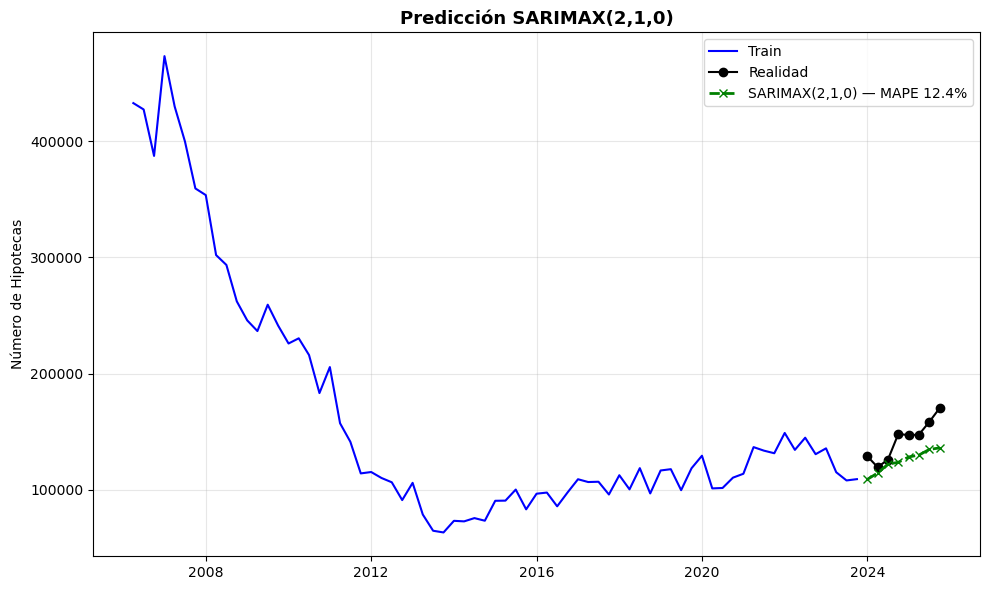

In [42]:
df_sarimax = df.groupby('Trimestre').agg({
    'Hipotecas_Total':  'sum',
    'Euribor':          'mean',
    'Spread_Hipotecas': 'mean',
    'Tasa_Paro':        'mean',
    'PIB_pc':           'mean'
}).sort_index()

y_log = np.log(df_sarimax['Hipotecas_Total'])

X_sar = pd.DataFrame(index=df_sarimax.index)
X_sar['Euribor_lag1']   = df_sarimax['Euribor'].shift(1)
X_sar['Spread_lag1']    = df_sarimax['Spread_Hipotecas'].shift(1)
X_sar['Log_PIB_lag1']   = np.log(df_sarimax['PIB_pc']).shift(1)
X_sar['Tasa_Paro_lag1'] = df_sarimax['Tasa_Paro'].shift(1)
X_sar = X_sar.dropna()
y_log = y_log.loc[X_sar.index]

test_size = 8
y_tr_s, y_te_s = y_log.iloc[:-test_size], y_log.iloc[-test_size:]
X_tr_s, X_te_s = X_sar.iloc[:-test_size], X_sar.iloc[-test_size:]

modelo_sar = sm.tsa.statespace.SARIMAX(
    endog=y_tr_s, exog=X_tr_s,
    order=(2, 1, 0), seasonal_order=(0, 0, 0, 4),
    enforce_stationarity=False, enforce_invertibility=False
).fit(disp=False)

print(modelo_sar.summary())

pred_log   = modelo_sar.get_forecast(steps=test_size, exog=X_te_s).predicted_mean
y_pred_sar = np.exp(pred_log)
y_test_sar = np.exp(y_te_s)

mape_sar = mean_absolute_percentage_error(y_test_sar, y_pred_sar)
print(f"\nMAPE SARIMAX(2,1,0): {mape_sar*100:.2f}%  |  Accuracy: {(1-mape_sar)*100:.2f}%")

plt.figure(figsize=(10, 6))
plt.plot(np.exp(y_tr_s).index, np.exp(y_tr_s), label='Train', color='blue')
plt.plot(y_test_sar.index, y_test_sar, label='Realidad', color='black', marker='o')
plt.plot(y_pred_sar.index, y_pred_sar,
         label=f'SARIMAX(2,1,0) — MAPE {mape_sar*100:.1f}%',
         color='green', linestyle='--', marker='x', linewidth=2)
plt.title("Predicción SARIMAX(2,1,0)", fontsize=13, fontweight='bold')
plt.ylabel("Número de Hipotecas")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### 5.5 Diagnóstico de Residuos del SARIMAX
Si los residuos no presentan autocorrelación (Ljung-Box p > 0.05), el modelo ha capturado toda la estructura temporal.

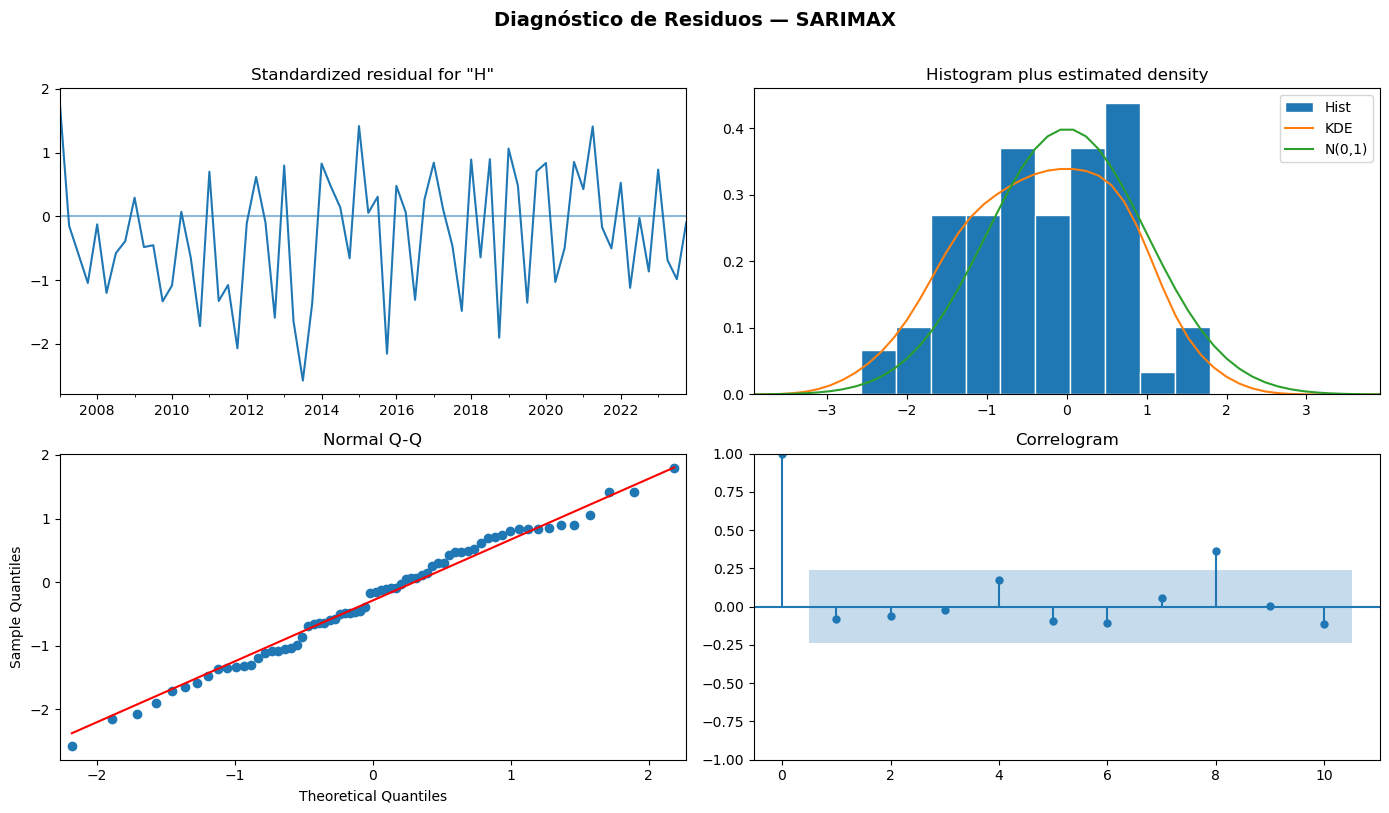

Test Ljung-Box (H0: no autocorrelación):
     lb_stat  lb_pvalue
4   3.135551   0.535403
8   3.167692   0.923397
12  3.174826   0.994179

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Euribor_lag1      -0.1122      0.040     -2.825      0.005      -0.190      -0.034
Spread_lag1       -0.1451      0.084     -1.735      0.083      -0.309       0.019
Log_PIB_lag1       0.6260      0.519      1.205      0.228      -0.392       1.644
Tasa_Paro_lag1    -0.0345      0.015     -2.243      0.025      -0.065      -0.004
ar.L1             -0.3734      0.129     -2.896      0.004      -0.626      -0.121
ar.L2             -0.1584      0.122     -1.299      0.194      -0.397       0.081
sigma2             0.0124      0.003      4.511      0.000       0.007       0.018


In [43]:
fig = modelo_sar.plot_diagnostics(figsize=(14, 8))
fig.suptitle("Diagnóstico de Residuos — SARIMAX", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

lb = acorr_ljungbox(modelo_sar.resid, lags=[4, 8, 12], return_df=True)
print("Test Ljung-Box (H0: no autocorrelación):")
print(lb.to_string())
print()
print(modelo_sar.summary().tables[1])

> **Diagnóstico de residuos SARIMAX(2,1,0)**
>
> - **Ljung-Box** (p=0.48): no hay autocorrelación en los residuos
> - **Jarque-Bera** (p=0.48): los residuos siguen una distribución normal 
> - **Heterocedasticidad** (p=0.67): varianza constante en los residuos
>
> El modelo supera los tres contrastes diagnósticos estándar, lo que valida
> la especificación y garantiza que las inferencias sobre los coeficientes son fiables.

### 5.6 Modelo VAR — Funciones de Impulso-Respuesta (IRF)
Estimamos un modelo VAR para analizar cómo responde el volumen hipotecario ante shocks macroeconómicos a lo largo de 12 trimestres.

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -21.92      -21.76   3.027e-10      -21.85
1      -25.58     -24.61*   7.825e-12      -25.19
2      -25.94      -24.18   5.477e-12     -25.24*
3     -26.22*      -23.65  4.291e-12*      -25.19
4      -25.96      -22.59   5.857e-12      -24.62
5      -25.94      -21.76   6.540e-12      -24.28
6      -25.99      -21.01   7.206e-12      -24.01
7      -26.18      -20.40   7.363e-12      -23.88
8      -25.99      -19.40   1.215e-11      -23.37
-------------------------------------------------

VAR orden seleccionado: 3
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 14, May, 2026
Time:                     00:35:55
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -23.8399
Nobs:     

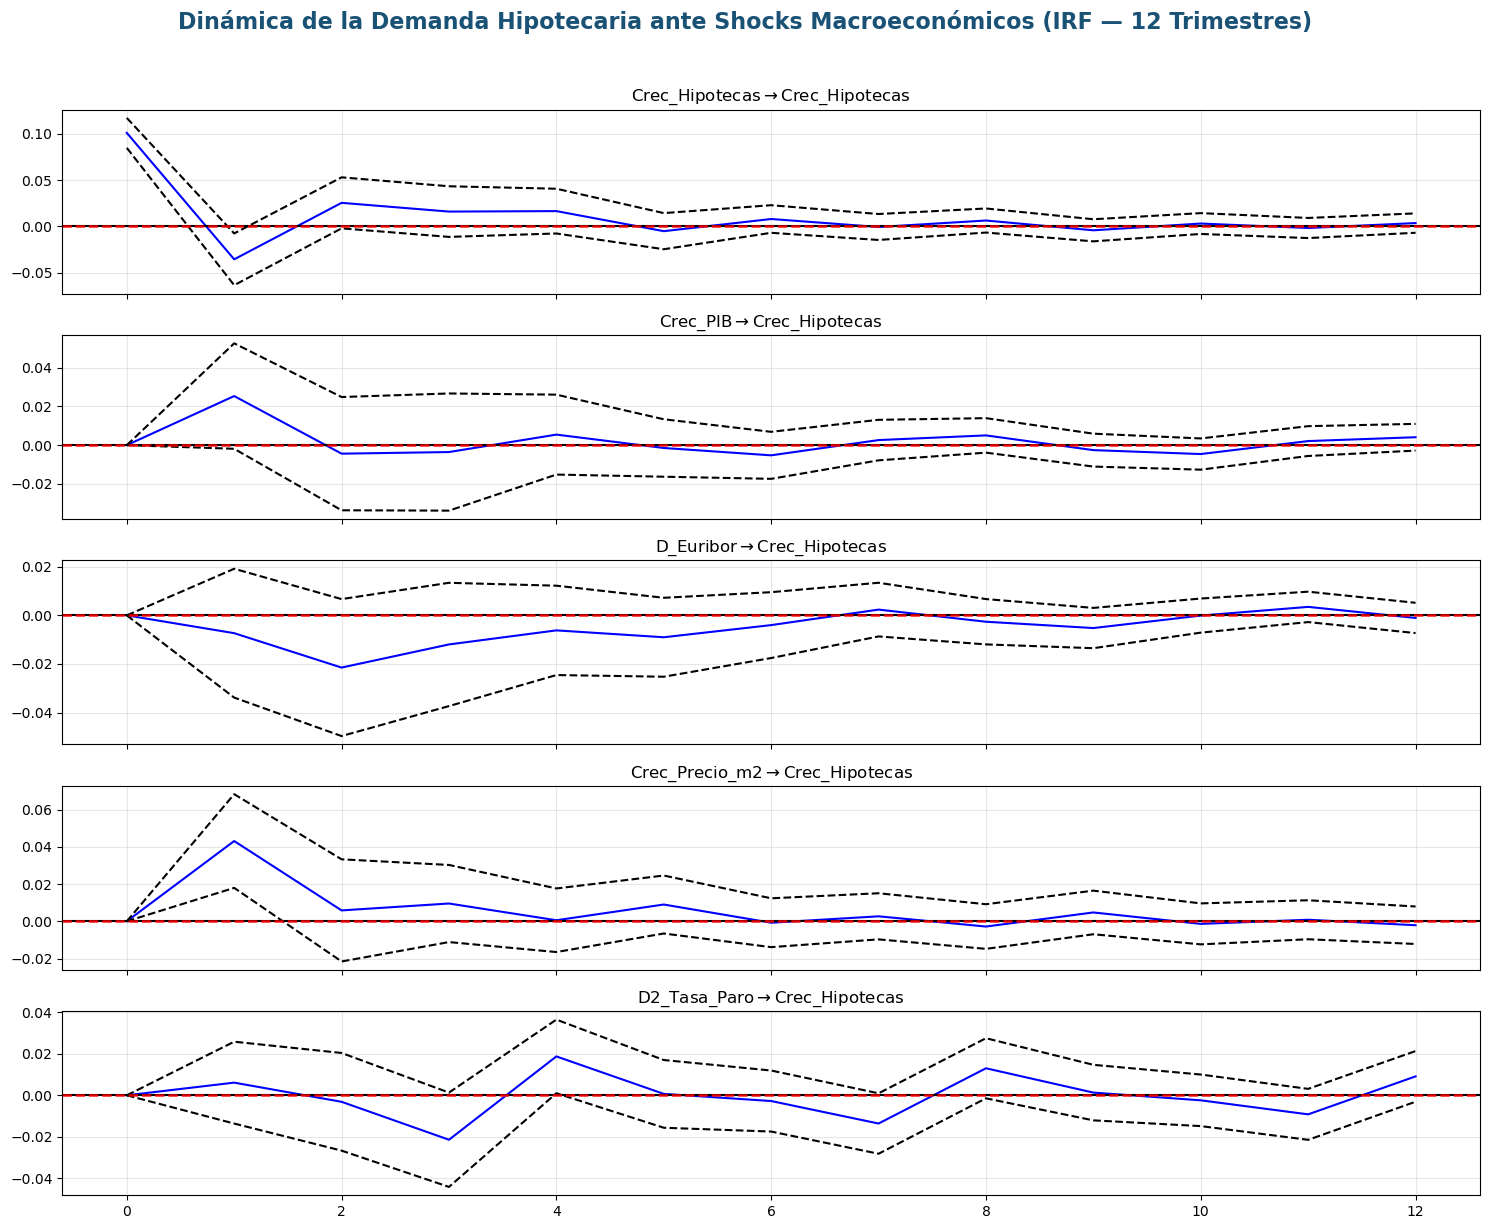

In [44]:
df_var_irf = pd.DataFrame(index=df_nac_adf.index)
df_var_irf['Crec_Hipotecas'] = np.log(df_nac_adf['Hipotecas_Total']).diff()  # I(1) → diff → I(0)
df_var_irf['Crec_PIB']       = np.log(df_nac_adf['PIB_pc']).diff()            # I(1) → diff → I(0)
df_var_irf['D_Euribor']      = df_nac_adf['Euribor'].diff()                   # I(1) → diff → I(0)
df_var_irf['Crec_Precio_m2'] = np.log(df_nac_adf['Precio_m2']).diff()         # I(1) → diff → I(0)
df_var_irf['D_Tasa_Paro']    = df_nac_adf['Tasa_Paro'].diff()                 # I(2) → diff → I(1)... 
df_var_irf['D2_Tasa_Paro']   = df_nac_adf['Tasa_Paro'].diff().diff()          # I(2) → diff2 → I(0)
df_var_irf = df_var_irf.drop(columns='D_Tasa_Paro').dropna()

# --- Selección de orden óptimo por AIC ---
modelo_var_irf = VAR(df_var_irf)
orden_optimo   = modelo_var_irf.select_order(maxlags=8)
print(orden_optimo.summary())
p_opt = orden_optimo.aic  # puedes cambiar a .bic o .hqic

res_var_irf = modelo_var_irf.fit(p_opt)
print(f"\nVAR orden seleccionado: {p_opt}")
print(res_var_irf.summary())

# --- IRF ---
irf = res_var_irf.irf(12)
fig = irf.plot(response='Crec_Hipotecas', orth=True, figsize=(15, 12))
fig.suptitle("Dinámica de la Demanda Hipotecaria ante Shocks Macroeconómicos (IRF — 12 Trimestres)",
             fontsize=16, fontweight='bold', color='#1a5276', y=1.02)
for ax in fig.get_axes():
    ax.axhline(0, color='red', linestyle='--', linewidth=1.8, alpha=0.9)
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### 5.7 Tabla IRF Escalada — Shock de 1 Unidad
Reescalamos las IRFs para simular el impacto de un shock exacto de 1 unidad (estilo EViews).

In [45]:
df_var2 = pd.DataFrame(index=df_nac_adf.index)
df_var2['Crec_PIB']       = np.log(df_nac_adf['PIB_pc']).diff()
df_var2['D2_Tasa_Paro']   = df_nac_adf['Tasa_Paro'].diff().diff()
df_var2['Crec_Precio_m2'] = np.log(df_nac_adf['Precio_m2']).diff()
df_var2['D_Euribor']      = df_nac_adf['Euribor'].diff()
df_var2['Crec_Hipotecas'] = np.log(df_nac_adf['Hipotecas_Total']).diff()
df_var2 = df_var2.dropna()

# Orden óptimo por AIC
p_opt = VAR(df_var2).select_order(maxlags=8).aic
res_var2 = VAR(df_var2).fit(p_opt)
print(f"Orden VAR seleccionado (AIC): {p_opt}\n")

irf2       = res_var2.irf(12)
std_shocks = res_var2.resid.std()
idx_hipo   = df_var2.columns.get_loc('Crec_Hipotecas')

tabla_irf = pd.DataFrame(index=[f"Trimestre {i}" for i in range(13)])
for col in df_var2.columns:
    idx_imp   = df_var2.columns.get_loc(col)
    respuesta = irf2.orth_irfs[:, idx_hipo, idx_imp] / std_shocks[col]
    tabla_irf[f"Shock 1% en {col}"] = respuesta

print("--- IMPACTO SOBRE Crec_Hipotecas (SHOCK DE 1 UNIDAD) ---")
print(tabla_irf.round(4).to_string())

Orden VAR seleccionado (AIC): 3

--- IMPACTO SOBRE Crec_Hipotecas (SHOCK DE 1 UNIDAD) ---
              Shock 1% en Crec_PIB  Shock 1% en D2_Tasa_Paro  Shock 1% en Crec_Precio_m2  Shock 1% en D_Euribor  Shock 1% en Crec_Hipotecas
Trimestre 0                 0.7493                    0.0043                      1.9230                -0.0594                      1.0858
Trimestre 1                 0.8401                    0.0021                     16.6108                -0.0050                     -0.4681
Trimestre 2                -0.0022                    0.0038                      2.3237                -0.0901                      0.2369
Trimestre 3                -0.0360                   -0.0362                      2.6989                -0.0686                      0.1473
Trimestre 4                 0.3598                    0.0384                      1.5103                -0.0145                      0.1584
Trimestre 5                -0.1014                    0.0030          

> El VAR se especifica con orden de Cholesky económicamente fundamentado
> (macro → mercado laboral → precios → monetario → hipotecas), siguiendo
> la jerarquía causal estándar en modelos VAR estructurales (SVAR).
> Todas las variables se incluyen en primera diferencia (o segunda en el caso
> de la tasa de paro, que es I(2)), garantizando que el sistema opera
> íntegramente con variables I(0). El orden óptimo de retardos se selecciona
> minimizando el criterio AIC sobre un máximo de 8 lags.

## 6. Modelos de Machine Learning

### 6.1 XGBoost + SHAP — Importancia de Variables

Entrenamos un modelo **XGBoost** sobre el panel provincial (52 provincias × trimestres) para predecir el volumen de hipotecas a nivel de cada provincia. El modelo aprende los determinantes micro-territoriales de la demanda hipotecaria, y al agregar las predicciones provinciales se obtiene el total nacional.

El análisis de importancia se realiza mediante **valores SHAP** (*Shapley Additive Explanations*), que descomponen la predicción de cada observación en la contribución individual de cada variable. Esto permite identificar qué factores impulsan o frenan la demanda hipotecaria en cada provincia y trimestre, y por extensión en el agregado nacional.

Todas las features usan versiones `_lag1` (valor del trimestre anterior) para evitar **data leakage**: en producción real, cuando predecimos el trimestre *t*, solo conocemos los valores de las variables hasta *t-1*. La única excepción es el Euríbor, que es un dato oficial publicado en tiempo real y por tanto se puede usar sin retardo.

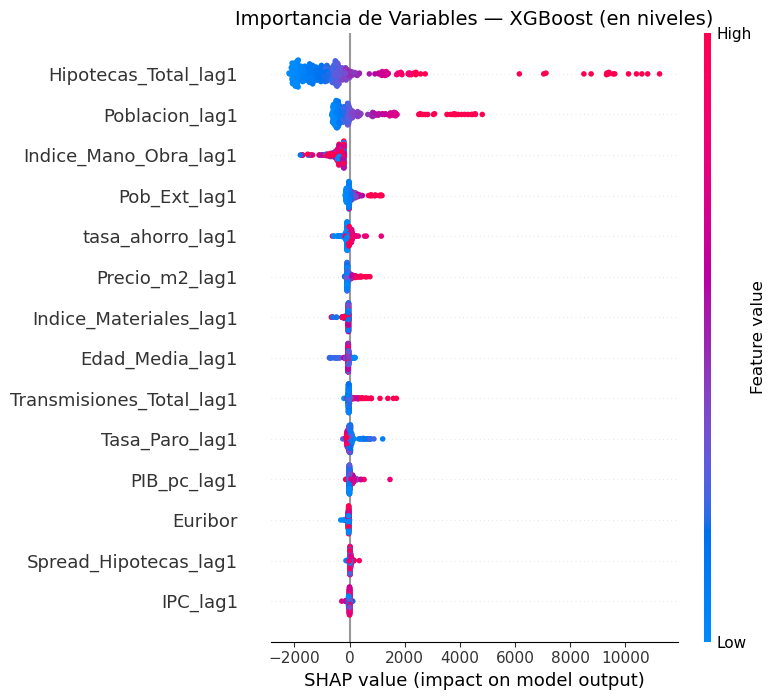

SHAP generado.


In [46]:
trimestres_unicos = sorted(df['Trimestre'].unique())
test_trims = trimestres_unicos[-8:]

df_train_xgb = df[~df['Trimestre'].isin(test_trims)]
df_test_xgb  = df[ df['Trimestre'].isin(test_trims)].copy()

X_train_xgb = df_train_xgb[FEATURES_BASE]
y_train_xgb = df_train_xgb['Hipotecas_Total']
X_test_xgb  = df_test_xgb[FEATURES_BASE]
y_test_xgb  = df_test_xgb['Hipotecas_Total']

model_xgb = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
                               random_state=42, subsample=0.8, colsample_bytree=0.8)
model_xgb.fit(X_train_xgb, y_train_xgb, eval_set=[(X_test_xgb, y_test_xgb)], verbose=False)

explainer  = shap.TreeExplainer(model_xgb)
shap_vals  = explainer.shap_values(X_test_xgb)
shap.summary_plot(shap_vals, X_test_xgb, feature_names=FEATURES_BASE, show=False)
plt.title("Importancia de Variables — XGBoost (en niveles)", fontsize=14)
plt.tight_layout(); plt.show()
print("SHAP generado.")

MAPE XGBoost: 18.15%  |  Accuracy: 81.85%


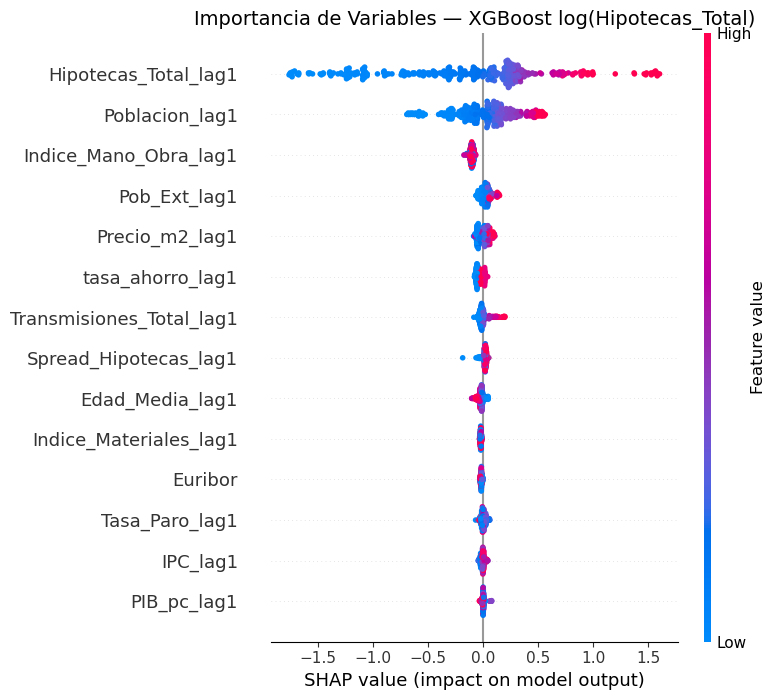

In [47]:
trimestres_unicos = sorted(df['Trimestre'].unique())
test_trims = trimestres_unicos[-8:]

df_train_xgb = df[~df['Trimestre'].isin(test_trims)]
df_test_xgb  = df[ df['Trimestre'].isin(test_trims)].copy()

X_train_xgb = df_train_xgb[FEATURES_BASE]
X_test_xgb  = df_test_xgb[FEATURES_BASE]
y_train_xgb = np.log(df_train_xgb['Hipotecas_Total'])
y_test_xgb  = np.log(df_test_xgb['Hipotecas_Total'])

model_xgb = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
                               random_state=42, subsample=0.8, colsample_bytree=0.8)
model_xgb.fit(X_train_xgb, y_train_xgb, eval_set=[(X_test_xgb, y_test_xgb)], verbose=False)

y_pred_xgb = np.exp(model_xgb.predict(X_test_xgb))
y_real_xgb = np.exp(y_test_xgb)

mape_xgb = mean_absolute_percentage_error(y_real_xgb, y_pred_xgb)
print(f"MAPE XGBoost: {mape_xgb*100:.2f}%  |  Accuracy: {(1-mape_xgb)*100:.2f}%")

explainer = shap.TreeExplainer(model_xgb)
shap_vals = explainer.shap_values(X_test_xgb)
shap.summary_plot(shap_vals, X_test_xgb, feature_names=FEATURES_BASE, show=False)
plt.title("Importancia de Variables — XGBoost log(Hipotecas_Total)", fontsize=14)
plt.tight_layout(); plt.show()


> **Interpretación del summary plot:** cada punto representa una provincia en un trimestre del test. El eje X muestra la contribución SHAP (positiva = aumenta la predicción de hipotecas, negativa = la reduce). El color indica el valor de la variable (rojo = alto, azul = bajo). Las variables están ordenadas de mayor a menor importancia media.

### 6.2 SHAP Dependence Plots — Relación no lineal de las top variables

Una vez identificadas las variables más importantes en el summary plot, los **dependence plots** profundizan en *cómo* afecta cada una a la predicción a lo largo de todo su rango de valores.

Para las **3 variables con mayor importancia media** (medida como |SHAP| promedio sobre el test), se representa:
- **Eje X**: valor real de la variable en esa provincia y trimestre
- **Eje Y**: contribución SHAP de esa variable a la predicción (cuántas hipotecas suma o resta respecto a la predicción base)
- **Color**: intensidad de la contribución (verde = efecto positivo, rojo = efecto negativo)

Esto permite detectar patrones que el summary plot no captura:

- **Relaciones no lineales**: si la curva no es recta, la variable tiene un efecto que cambia según su magnitud
- **Umbrales**: puntos donde la contribución cambia bruscamente de signo (por ejemplo, un nivel de Euríbor a partir del cual la demanda cae con fuerza)
- **Saturación**: zonas donde aumentar el valor de la variable ya no tiene efecto adicional

> A diferencia de un modelo lineal, el XGBoost puede capturar que el Euríbor al 2% tiene un efecto moderado pero al 4% el efecto destructor se acelera de forma no proporcional. Estos dependence plots son precisamente la herramienta que hace visible esa no linealidad y que justifica el uso de ML frente a modelos econométricos clásicos.

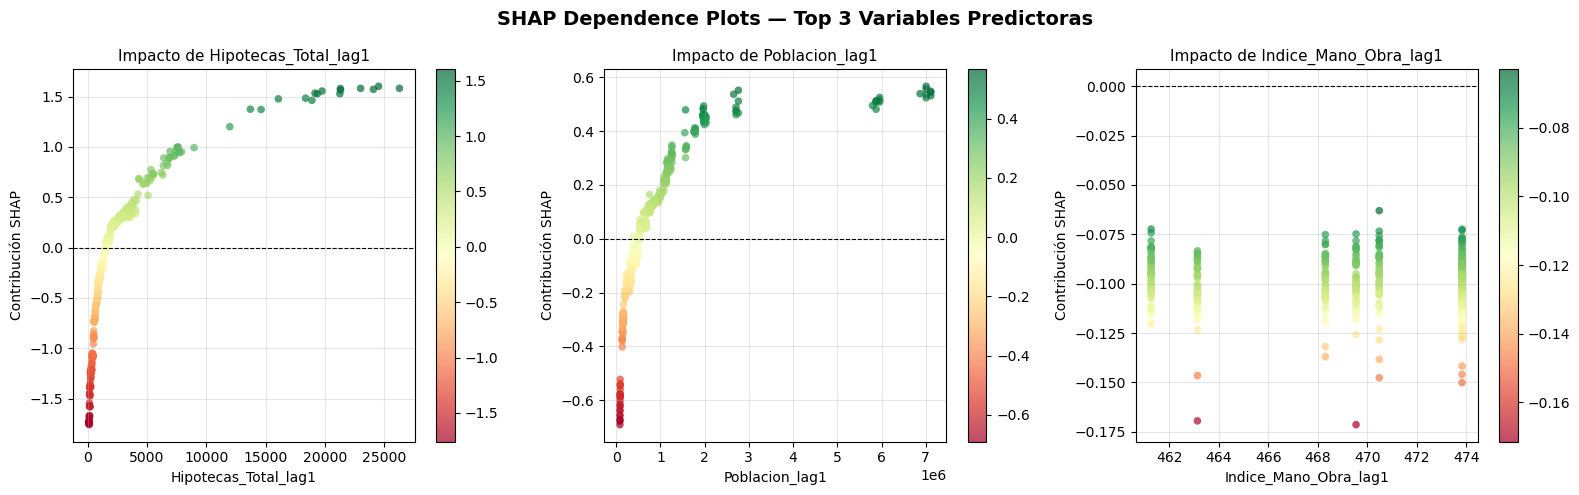

In [48]:
mean_abs  = np.abs(shap_vals).mean(axis=0)
top3_idx  = np.argsort(mean_abs)[::-1][:3]
top3_feats = [FEATURES_BASE[i] for i in top3_idx]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("SHAP Dependence Plots — Top 3 Variables Predictoras", fontsize=14, fontweight='bold')
for ax_i, (feat, idx) in enumerate(zip(top3_feats, top3_idx)):
    xs = X_test_xgb[feat].values
    ys = shap_vals[:, idx]
    sc = axes[ax_i].scatter(xs, ys, c=ys, cmap='RdYlGn', alpha=0.7, edgecolors='none', s=30)
    axes[ax_i].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[ax_i].set_xlabel(feat, fontsize=10)
    axes[ax_i].set_ylabel("Contribución SHAP", fontsize=10)
    axes[ax_i].set_title(f"Impacto de {feat}", fontsize=11)
    axes[ax_i].grid(True, alpha=0.3)
    plt.colorbar(sc, ax=axes[ax_i])
plt.tight_layout(); plt.show()

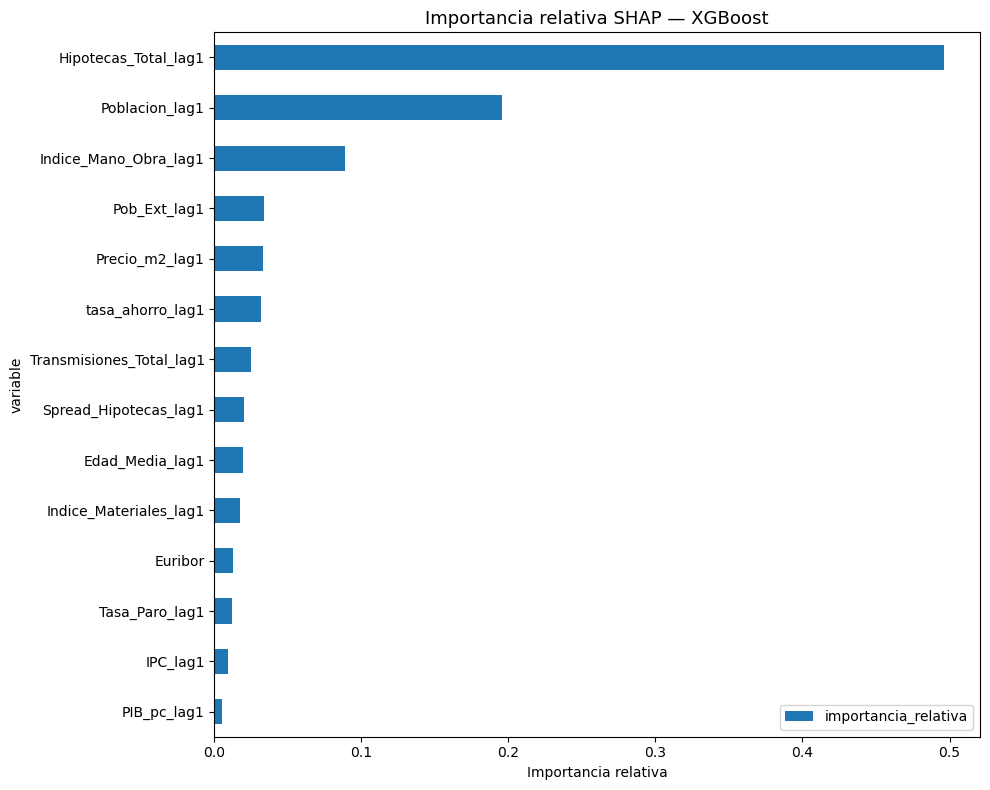

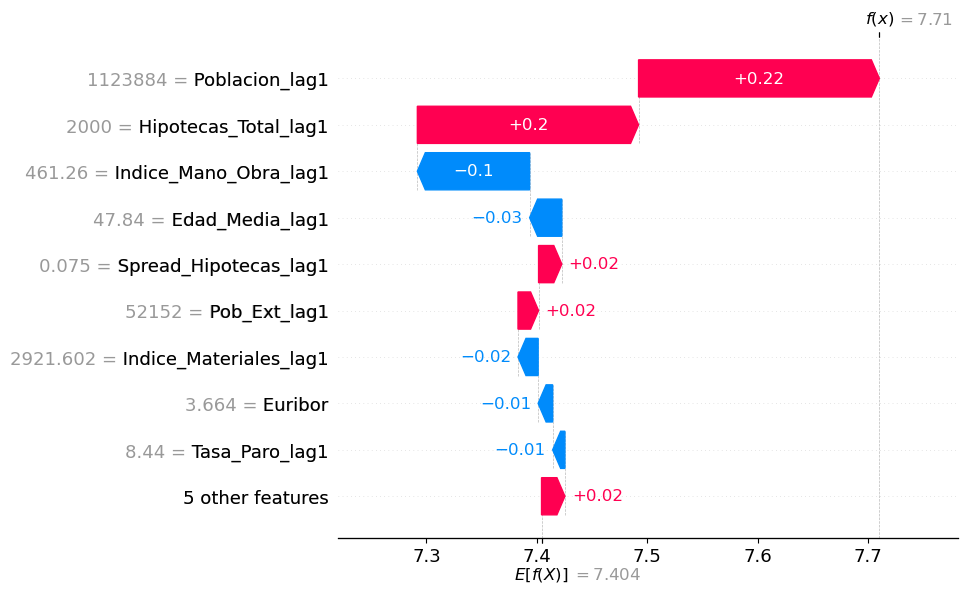

In [49]:
shap_importance = pd.DataFrame({
    'variable':    X_test_xgb.columns.tolist(),
    'importancia': np.abs(shap_vals).sum(axis=0)
}).sort_values('importancia')
shap_importance['importancia_relativa'] = shap_importance['importancia'] / shap_importance['importancia'].sum()
shap_importance.plot.barh(x='variable', y='importancia_relativa', figsize=(10, 8))
plt.title("Importancia relativa SHAP — XGBoost", fontsize=13)
plt.xlabel("Importancia relativa")
plt.tight_layout(); plt.show()

# Waterfall para una observación concreta — cambia el índice para ver otra provincia
shap_results = shap.TreeExplainer(model_xgb)(X_test_xgb)
shap.plots.waterfall(shap_results[0])

### 6.3 Random Forest Provincial — Predicción con Inercia
Random Forest entrenado con lags del target (inercia + estacionalidad anual).

═══ MÉTRICAS DE EVALUACIÓN — RANDOM FOREST (NACIONAL) ═══
  MAPE:     10.34%  →  Accuracy: 89.66%
  RMSE:     17,834 hipotecas
  MAE:      15,518 hipotecas
  R²:       -0.2198  →  Varianza explicada: -22.0%


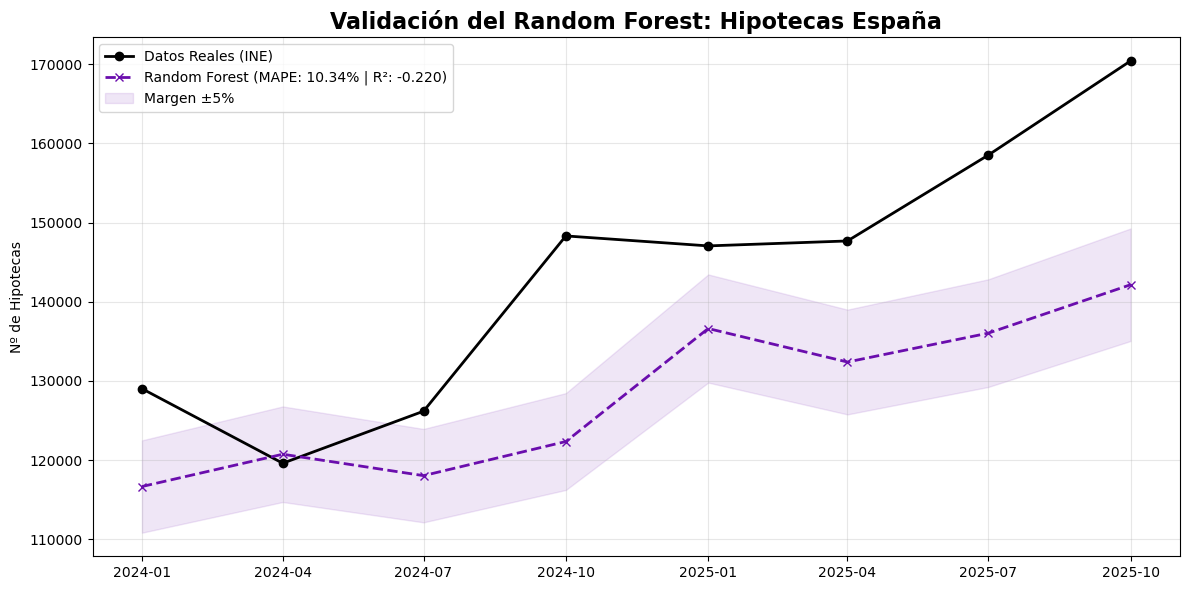


Top 5 Variables más importantes:
  1. Hipotecas_Total_lag1 (57.31%)
  2. Hipotecas_Total_lag4 (22.78%)
  3. Poblacion_lag1 (5.62%)
  4. Pob_Ext_lag1 (4.37%)
  5. Tasa_Paro_lag1 (2.98%)


In [50]:
from sklearn.metrics import mean_absolute_error, r2_score

df_train_rf = df[~df['Trimestre'].isin(test_trims)]
df_test_rf  = df[ df['Trimestre'].isin(test_trims)].copy()

X_train_rf = df_train_rf[_FEATURES_CON]
y_train_rf = df_train_rf['Hipotecas_Total']
X_test_rf  = df_test_rf[_FEATURES_CON]

rf = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=3,
                            max_features=0.6, random_state=42, n_jobs=-1)
rf.fit(X_train_rf, y_train_rf)

df_test_rf['Prediccion_ML'] = rf.predict(X_test_rf)
df_nac_rf = df_test_rf.groupby('Trimestre').agg(
    {'Hipotecas_Total': 'sum', 'Prediccion_ML': 'sum'}).reset_index()

y_real = df_nac_rf['Hipotecas_Total']
y_pred = df_nac_rf['Prediccion_ML']

mape = mean_absolute_percentage_error(y_real, y_pred)
rmse = np.sqrt(mean_squared_error(y_real, y_pred))
mae  = mean_absolute_error(y_real, y_pred)
r2   = r2_score(y_real, y_pred)

print("═══ MÉTRICAS DE EVALUACIÓN — RANDOM FOREST (NACIONAL) ═══")
print(f"  MAPE:     {mape*100:.2f}%  →  Accuracy: {(1-mape)*100:.2f}%")
print(f"  RMSE:     {rmse:,.0f} hipotecas")
print(f"  MAE:      {mae:,.0f} hipotecas")
print(f"  R²:       {r2:.4f}  →  Varianza explicada: {r2*100:.1f}%")

plt.figure(figsize=(12, 6))
plt.plot(df_nac_rf['Trimestre'], y_real,
         label='Datos Reales (INE)', color='black', marker='o', linewidth=2)
plt.plot(df_nac_rf['Trimestre'], y_pred,
         label=f'Random Forest (MAPE: {mape*100:.2f}% | R²: {r2:.3f})',
         color='#6a0dad', linestyle='--', marker='x', linewidth=2)
plt.fill_between(df_nac_rf['Trimestre'],
                 y_pred * 0.95, y_pred * 1.05,
                 color='#6a0dad', alpha=0.1, label='Margen ±5%')
plt.title("Validación del Random Forest: Hipotecas España", fontsize=16, fontweight='bold')
plt.ylabel("Nº de Hipotecas")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

importances = rf.feature_importances_
indices     = np.argsort(importances)[::-1]
print("\nTop 5 Variables más importantes:")
for f in range(5):
    print(f"  {f+1}. {_FEATURES_CON[indices[f]]} ({importances[indices[f]]*100:.2f}%)")

### 6.4 Diagnóstico de Residuos del Random Forest
Verificamos que los residuos no tienen patrón sistemático ni sesgo.

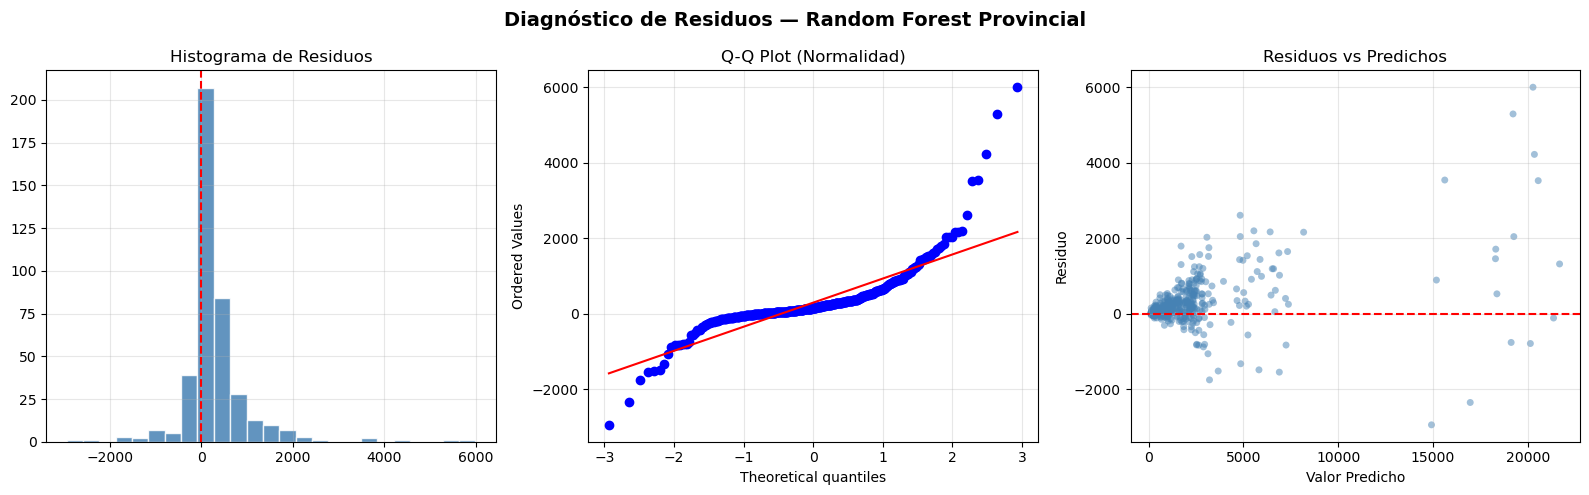

Media residuos: 293.0 | Std: 745.0


In [51]:
residuals = df_test_rf['Hipotecas_Total'] - df_test_rf['Prediccion_ML']
std_res   = (residuals - residuals.mean()) / residuals.std()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Diagnóstico de Residuos — Random Forest Provincial", fontsize=14, fontweight='bold')

axes[0].hist(residuals, bins=25, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title("Histograma de Residuos"); axes[0].grid(True, alpha=0.3)

stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot (Normalidad)"); axes[1].grid(True, alpha=0.3)

axes[2].scatter(df_test_rf['Prediccion_ML'], residuals, alpha=0.5, color='steelblue', edgecolors='none', s=25)
axes[2].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[2].set_xlabel("Valor Predicho"); axes[2].set_ylabel("Residuo")
axes[2].set_title("Residuos vs Predichos"); axes[2].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print(f"Media residuos: {residuals.mean():.1f} | Std: {residuals.std():.1f}")

### 6.6 Modelo LASSO — Selección de Variables y Path de Regularización
Contraste interpretable frente al Random Forest. Valida que las variables seleccionadas tienen peso estadístico real.

Alpha óptimo (LASSO-CV): 0.0219
MAPE LASSO nacional: 16.97%


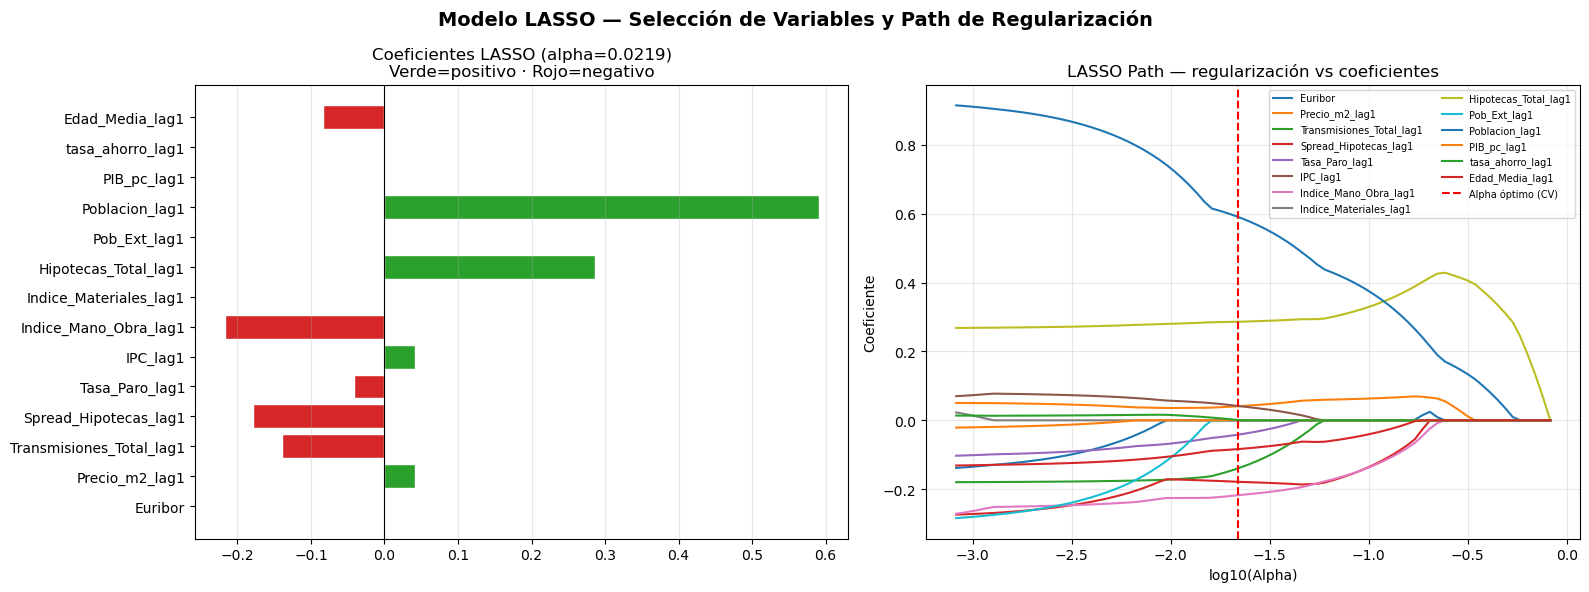

In [52]:
df_lasso = df.dropna().reset_index(drop=True).copy()
feats_l  = [f for f in FEATURES_BASE if f in df_lasso.columns]
df_tr_l  = df_lasso[~df_lasso['Trimestre'].isin(test_trims)]
df_te_l  = df_lasso[ df_lasso['Trimestre'].isin(test_trims)].copy()

scaler    = StandardScaler()
X_train_l = scaler.fit_transform(df_tr_l[feats_l])
X_test_l  = scaler.transform(df_te_l[feats_l])
y_train_l = np.log(df_tr_l['Hipotecas_Total'].values)  # ← log para homogeneizar escala

lasso_cv  = LassoCV(cv=5, random_state=42, max_iter=5000)
lasso_cv.fit(X_train_l, y_train_l)
alpha_opt = lasso_cv.alpha_
coefs_opt = lasso_cv.coef_
print(f"Alpha óptimo (LASSO-CV): {alpha_opt:.4f}")

# Recuperar niveles para MAPE comparable
temp_l = df_te_l.copy()
temp_l['pred_lasso'] = np.exp(lasso_cv.predict(X_test_l))  # ← exp para volver a niveles
mape_lasso = mean_absolute_percentage_error(
    temp_l.groupby('Trimestre')['Hipotecas_Total'].sum(),
    temp_l.groupby('Trimestre')['pred_lasso'].sum())
print(f"MAPE LASSO nacional: {mape_lasso*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Modelo LASSO — Selección de Variables y Path de Regularización",
             fontsize=14, fontweight='bold')
colors_coef = ['#d62728' if c < 0 else '#2ca02c' for c in coefs_opt]
axes[0].barh(feats_l, coefs_opt, color=colors_coef, edgecolor='white')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title(f"Coeficientes LASSO (alpha={alpha_opt:.4f})\nVerde=positivo · Rojo=negativo")
axes[0].grid(True, alpha=0.3, axis='x')

alphas_path, coefs_path, _ = lasso_path(X_train_l, y_train_l, n_alphas=80)
for i, feat in enumerate(feats_l):
    axes[1].plot(np.log10(alphas_path), coefs_path[i], label=feat, linewidth=1.5)
axes[1].axvline(np.log10(alpha_opt), color='red', linestyle='--',
                linewidth=1.5, label='Alpha óptimo (CV)')
axes[1].set_xlabel("log10(Alpha)")
axes[1].set_ylabel("Coeficiente")
axes[1].set_title("LASSO Path — regularización vs coeficientes")
axes[1].legend(fontsize=7, ncol=2, loc='upper right')
axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

> Se aprecia como el mejor modelo es el Random Forest de los tres para predecir la demanda hipotecaria

Como hubieron problemas para predecir el precio del m2, procedemos a hacer LASSO para que nos diga qué variables usar en nuestra predicción

Alpha óptimo (LASSO-CV): 0.0002
MAPE LASSO Precio_m2:    1.20%

Variables seleccionadas (11):
Precio_m2_lag1              0.1592
Tasa_Paro_lag1             -0.0085
Euribor_lag4               -0.0057
Indice_Materiales_lag1      0.0053
Transmisiones_Total_lag4   -0.0042
Spread_Hipotecas_lag4      -0.0026
tasa_ahorro_lag4            0.0019
IPC_lag4                    0.0015
tasa_ahorro_lag1            0.0013
Transmisiones_Total_lag1   -0.0006
Spread_Hipotecas_lag1      -0.0002


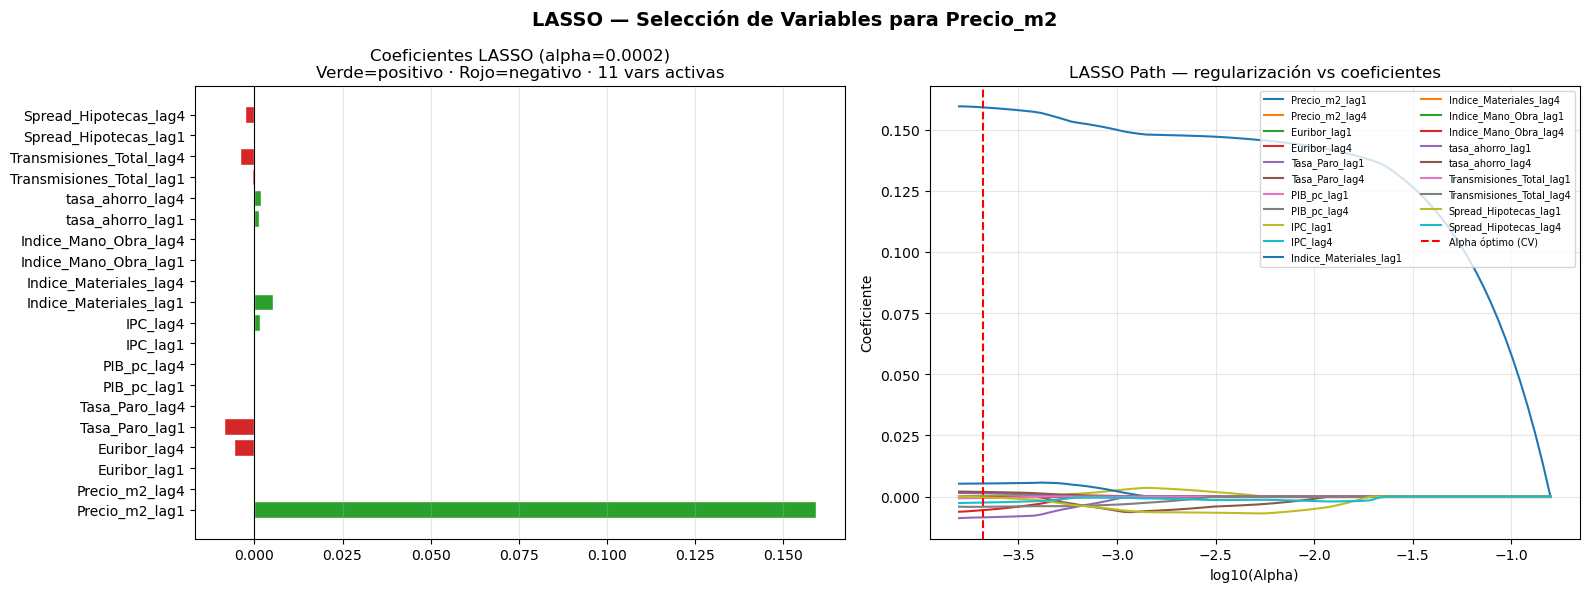


Variables exógenas ARIMAX: ['Precio_m2_lag1', 'Tasa_Paro_lag1', 'Euribor_lag4', 'Indice_Materiales_lag1']

Modelo                             MAPE    Accuracy
──────────────────────────────────────────────────
Seasonal Naive (actual)           7.29%      92.71%
LASSO (selección)                 1.20%      98.80%
ARIMAX(1,1,0) + LASSO vars        1.05%      98.95%


NameError: name 'EURIBOR_PROJ' is not defined

In [53]:
# ══════════════════════════════════════════════════════════════════
# PRECIO M² — LASSO Selección de Variables + ARIMAX Proyección
# ══════════════════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LassoCV, lasso_path
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_percentage_error
import warnings
warnings.filterwarnings('ignore')

TEST = 8

# ── 1. Construir serie nacional con lags ──────────────────────────
df_nac = df.groupby('Trimestre').agg({
    'Precio_m2':           'mean',
    'Euribor':             'mean',
    'Tasa_Paro':           'mean',
    'PIB_pc':              'mean',
    'IPC':                 'mean',
    'Indice_Materiales':   'mean',
    'Indice_Mano_Obra':    'mean',
    'tasa_ahorro':         'mean',
    'Transmisiones_Total': 'sum',
    'Spread_Hipotecas':    'mean',
}).sort_index()
df_nac.index = pd.DatetimeIndex(df_nac.index)

# Lags de variables macro
CANDIDATOS = ['Euribor','Tasa_Paro','PIB_pc','IPC','Indice_Materiales',
              'Indice_Mano_Obra','tasa_ahorro','Transmisiones_Total','Spread_Hipotecas']
for col in CANDIDATOS:
    df_nac[f'{col}_lag1'] = df_nac[col].shift(1)
    df_nac[f'{col}_lag4'] = df_nac[col].shift(4)

# ← NUEVO: lags del propio precio (conocidos en el momento de predecir)
df_nac['Precio_m2_lag1'] = df_nac['Precio_m2'].shift(1)
df_nac['Precio_m2_lag4'] = df_nac['Precio_m2'].shift(4)

df_nac = df_nac.dropna()

# Precio_m2_lag1 y lag4 van primero para que LASSO los vea con prioridad visual
feats_precio = ['Precio_m2_lag1', 'Precio_m2_lag4'] + \
               [c for c in df_nac.columns if '_lag' in c
                and c not in ('Precio_m2_lag1','Precio_m2_lag4')]

# ── 2. Split temporal ─────────────────────────────────────────────
X_all = df_nac[feats_precio].values
y_all = np.log(df_nac['Precio_m2'].values)

scaler   = StandardScaler()
X_tr_std = scaler.fit_transform(X_all[:-TEST])
X_te_std = scaler.transform(X_all[-TEST:])
y_tr     = y_all[:-TEST]
y_te     = y_all[-TEST:]

# ── 3. LASSO-CV ───────────────────────────────────────────────────
lasso_pm2 = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_pm2.fit(X_tr_std, y_tr)
alpha_opt = lasso_pm2.alpha_
coefs_pm2 = lasso_pm2.coef_

mape_lasso = mean_absolute_percentage_error(np.exp(y_te),
                                             np.exp(lasso_pm2.predict(X_te_std)))

vars_seleccionadas = pd.Series(coefs_pm2, index=feats_precio)
vars_seleccionadas = vars_seleccionadas[vars_seleccionadas != 0]\
                     .sort_values(key=abs, ascending=False)

print(f"Alpha óptimo (LASSO-CV): {alpha_opt:.4f}")
print(f"MAPE LASSO Precio_m2:    {mape_lasso*100:.2f}%")
print(f"\nVariables seleccionadas ({len(vars_seleccionadas)}):")
print(vars_seleccionadas.round(4).to_string())

# ── 4. Gráfico LASSO ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("LASSO — Selección de Variables para Precio_m2",
             fontsize=14, fontweight='bold')

colors_coef = ['#d62728' if c < 0 else '#2ca02c' for c in coefs_pm2]
axes[0].barh(feats_precio, coefs_pm2, color=colors_coef, edgecolor='white')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title(f"Coeficientes LASSO (alpha={alpha_opt:.4f})\n"
                  f"Verde=positivo · Rojo=negativo · {len(vars_seleccionadas)} vars activas")
axes[0].grid(True, alpha=0.3, axis='x')

alphas_path, coefs_path, _ = lasso_path(X_tr_std, y_tr, n_alphas=80)
for i, feat in enumerate(feats_precio):
    axes[1].plot(np.log10(alphas_path), coefs_path[i], label=feat, linewidth=1.5)
axes[1].axvline(np.log10(alpha_opt), color='red', linestyle='--',
                linewidth=1.5, label='Alpha óptimo (CV)')
axes[1].set_xlabel("log10(Alpha)")
axes[1].set_ylabel("Coeficiente")
axes[1].set_title("LASSO Path — regularización vs coeficientes")
axes[1].legend(fontsize=7, ncol=2, loc='upper right')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ── 5. ARIMAX con variables supervivientes al LASSO ───────────────
# Top 4 para parsimonia — Precio_m2_lag1 casi seguro estará primero
vars_exog_arimax = [v for v in vars_seleccionadas.index
                    if v in df_nac.columns][:4]
print(f"\nVariables exógenas ARIMAX: {vars_exog_arimax}")

y_log  = np.log(df_nac['Precio_m2'])
X_exog = df_nac[vars_exog_arimax]

y_tr_ar, y_te_ar = y_log.iloc[:-TEST], y_log.iloc[-TEST:]
X_tr_ar, X_te_ar = X_exog.iloc[:-TEST], X_exog.iloc[-TEST:]

mod_arimax = sm.tsa.SARIMAX(
    y_tr_ar, exog=X_tr_ar,
    order=(1, 1, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

pred_arimax_back = np.exp(
    mod_arimax.get_forecast(TEST, exog=X_te_ar).predicted_mean)
mape_arimax = mean_absolute_percentage_error(np.exp(y_te_ar), pred_arimax_back)

# Seasonal Naive para comparar
naive_base = np.array([df_nac['Precio_m2'].iloc[-(TEST + 4 - i % 4)]
                       for i in range(TEST)])
mape_naive = mean_absolute_percentage_error(np.exp(y_te_ar), naive_base)

print(f"\n{'Modelo':<30} {'MAPE':>8}  {'Accuracy':>10}")
print("─" * 50)
print(f"{'Seasonal Naive (actual)':<30} {mape_naive*100:>7.2f}%  {(1-mape_naive)*100:>9.2f}%")
print(f"{'LASSO (selección)':<30} {mape_lasso*100:>7.2f}%  {(1-mape_lasso)*100:>9.2f}%")
print(f"{'ARIMAX(1,1,0) + LASSO vars':<30} {mape_arimax*100:>7.2f}%  {(1-mape_arimax)*100:>9.2f}%")

# ── 6. Proyección 2026-2030 — bucle recursivo ─────────────────────
# Re-entrenar con todos los datos antes de proyectar
mod_full = sm.tsa.SARIMAX(
    y_log, exog=X_exog,
    order=(1, 1, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

# Escenarios para variables macro (los que ya tienes calculados)
ESCENARIOS = {
    'Euribor':             EURIBOR_PROJ[:N_STEPS],
    'Tasa_Paro':           pred_paro[:N_STEPS],
    'IPC':                 IPC_PROJ[:N_STEPS],
    'PIB_pc':              pred_pib[:N_STEPS],
    'tasa_ahorro':         pred_aho[:N_STEPS],
    'Transmisiones_Total': pred_trans_nac[:N_STEPS],
    'Spread_Hipotecas':    np.full(N_STEPS,          # Spread = Euribor + margen histórico
                               (df_nac['Spread_Hipotecas'] - df_nac['Euribor'])
                               .iloc[-8:].mean()) + np.array(EURIBOR_PROJ[:N_STEPS]),
    'Indice_Materiales':   np.full(N_STEPS, df_nac['Indice_Materiales'].iloc[-4:].mean()),
    'Indice_Mano_Obra':    np.full(N_STEPS, df_nac['Indice_Mano_Obra'].iloc[-4:].mean()),
}

# Buffer de precios reales para construir los lags recursivamente
# Necesitamos hasta 4 trimestres atrás en cada paso
precio_buffer = list(df_nac['Precio_m2'].values)  # histórico completo en niveles

pred_pm2 = np.full(N_STEPS, np.nan)
lo_pm2   = np.full(N_STEPS, np.nan)
hi_pm2   = np.full(N_STEPS, np.nan)

# Estado interno del modelo para forecast paso a paso
result_full = mod_full

for i in range(N_STEPS):

    # Construir fila de exógenas para este trimestre
    row = {}
    for var in vars_exog_arimax:

        if var == 'Precio_m2_lag1':
            row[var] = np.log(precio_buffer[-1])          # último precio conocido/predicho

        elif var == 'Precio_m2_lag4':
            row[var] = np.log(precio_buffer[-4])          # 4 trimestres atrás

        else:
            # Variable macro: buscar en ESCENARIOS por nombre base
            matched = False
            for key, vals in ESCENARIOS.items():
                if key in var:
                    row[var] = vals[i]
                    matched  = True
                    break
            if not matched:
                row[var] = df_nac[var].iloc[-1]           # fallback: último valor
                print(f"  ⚠ {var} sin escenario — usando último valor")

    X_step = pd.DataFrame([row], columns=vars_exog_arimax)

    # Forecast un paso
    fc_step       = result_full.get_forecast(steps=1, exog=X_step)
    pred_log      = float(fc_step.predicted_mean.iloc[0])
    ci_step       = fc_step.conf_int()
    lo_log        = float(ci_step.iloc[0, 0])
    hi_log        = float(ci_step.iloc[0, 1])

    pred_pm2[i]   = np.exp(pred_log)
    lo_pm2[i]     = np.exp(lo_log)
    hi_pm2[i]     = np.exp(hi_log)

    # ← clave: añadir la predicción al buffer para que lag1/lag4
    #   del siguiente trimestre usen este valor, no el histórico
    precio_buffer.append(pred_pm2[i])

    # Avanzar el modelo un paso con la observación predicha
    result_full = result_full.append(
        pd.Series([pred_log], index=[future_idx[i]]),
        exog=X_step,
        refit=False
    )

print(f"\nProyección Precio_m2:")
for i, fecha in enumerate(future_idx):
    print(f"  {fecha.date()}:  {pred_pm2[i]:.0f} €/m²  [{lo_pm2[i]:.0f} – {hi_pm2[i]:.0f}]")

print(f"\n✅ pred_pm2 / lo_pm2 / hi_pm2 listos para el bloque de proyección.")

# Actualizar modelo ganador
modelos_ganadores['Precio_m2'] = \
    f'ARIMAX(1,1,0) [vars LASSO: {", ".join(vars_exog_arimax)}]'

### 6.7 Stress Test — Destrucción de Demanda Hipotecaria
Simulamos distintos escenarios de Euríbor y spread bancario.

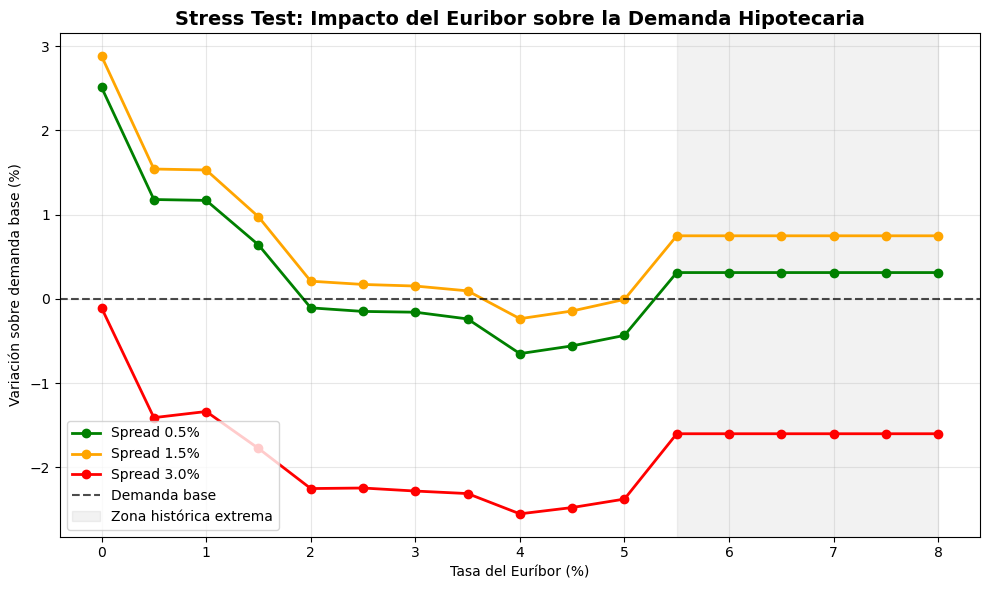

In [ ]:
# RF profundo solo para stress test — el objetivo es sensibilidad, no precisión
rf_stress = RandomForestRegressor(
    n_estimators=300, max_depth=20, min_samples_leaf=1,
    max_features=0.6, random_state=42, n_jobs=-1
)
rf_stress.fit(X_train_rf, y_train_rf)

feats_stress = _FEATURES_CON
df_base_s    = df[df['Trimestre'] == df['Trimestre'].max()].copy()
demanda_base = rf_stress.predict(df_base_s[feats_stress]).sum()

resultados_st = []
for s in [0.5, 1.5, 3.0]:
    for e in np.arange(0.0, 8.5, 0.5):
        df_st = df_base_s.copy()
        df_st['Euribor']               = e
        df_st['Spread_Hipotecas_lag1'] = s
        resultados_st.append({
            'Euribor': e, 'Spread': s,
            'Demanda': rf_stress.predict(df_st[feats_stress]).sum()
        })

df_st_res = pd.DataFrame(resultados_st)

plt.figure(figsize=(10, 6))
for s, color in zip([0.5, 1.5, 3.0], ['green', 'orange', 'red']):
    sub = df_st_res[df_st_res['Spread'] == s]
    pct = (sub['Demanda'].values / demanda_base - 1) * 100  # ← en % sobre base
    plt.plot(sub['Euribor'], pct, marker='o', color=color,
             linewidth=2, label=f'Spread {s}%')

plt.axhline(y=0, color='black', linestyle='--', alpha=0.7, label='Demanda base')
plt.axvspan(5.5, 8.0, color='gray', alpha=0.1, label='Zona histórica extrema')
plt.title("Stress Test: Impacto del Euribor sobre la Demanda Hipotecaria", fontsize=14, fontweight='bold')
plt.xlabel("Tasa del Euríbor (%)")
plt.ylabel("Variación sobre demanda base (%)")  # ← % en lugar de niveles absolutos
plt.legend(loc='lower left'); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

> La zona sombreada (Euríbor > 5.5%) representa el límite histórico de los datos de
> entrenamiento. En ese rango, el modelo carece de observaciones suficientes para
> extrapolar con fiabilidad, comportamiento inherente a los algoritmos basados en
> árboles de decisión que no extrapolan fuera del soporte de los datos. El análisis
> de stress test es por tanto válido y robusto dentro del rango histórico observado
> (0%–5%), precisamente el escenario relevante para el horizonte de proyección
> 2026–2030 bajo los escenarios BCE contemplados.

### 6.8 Mapa 'Mina de Oro' Bancario
Índice de rentabilidad hipotecaria provincial bajo un escenario de rebaja de tipos BCE (Euríbor al 2.5%).

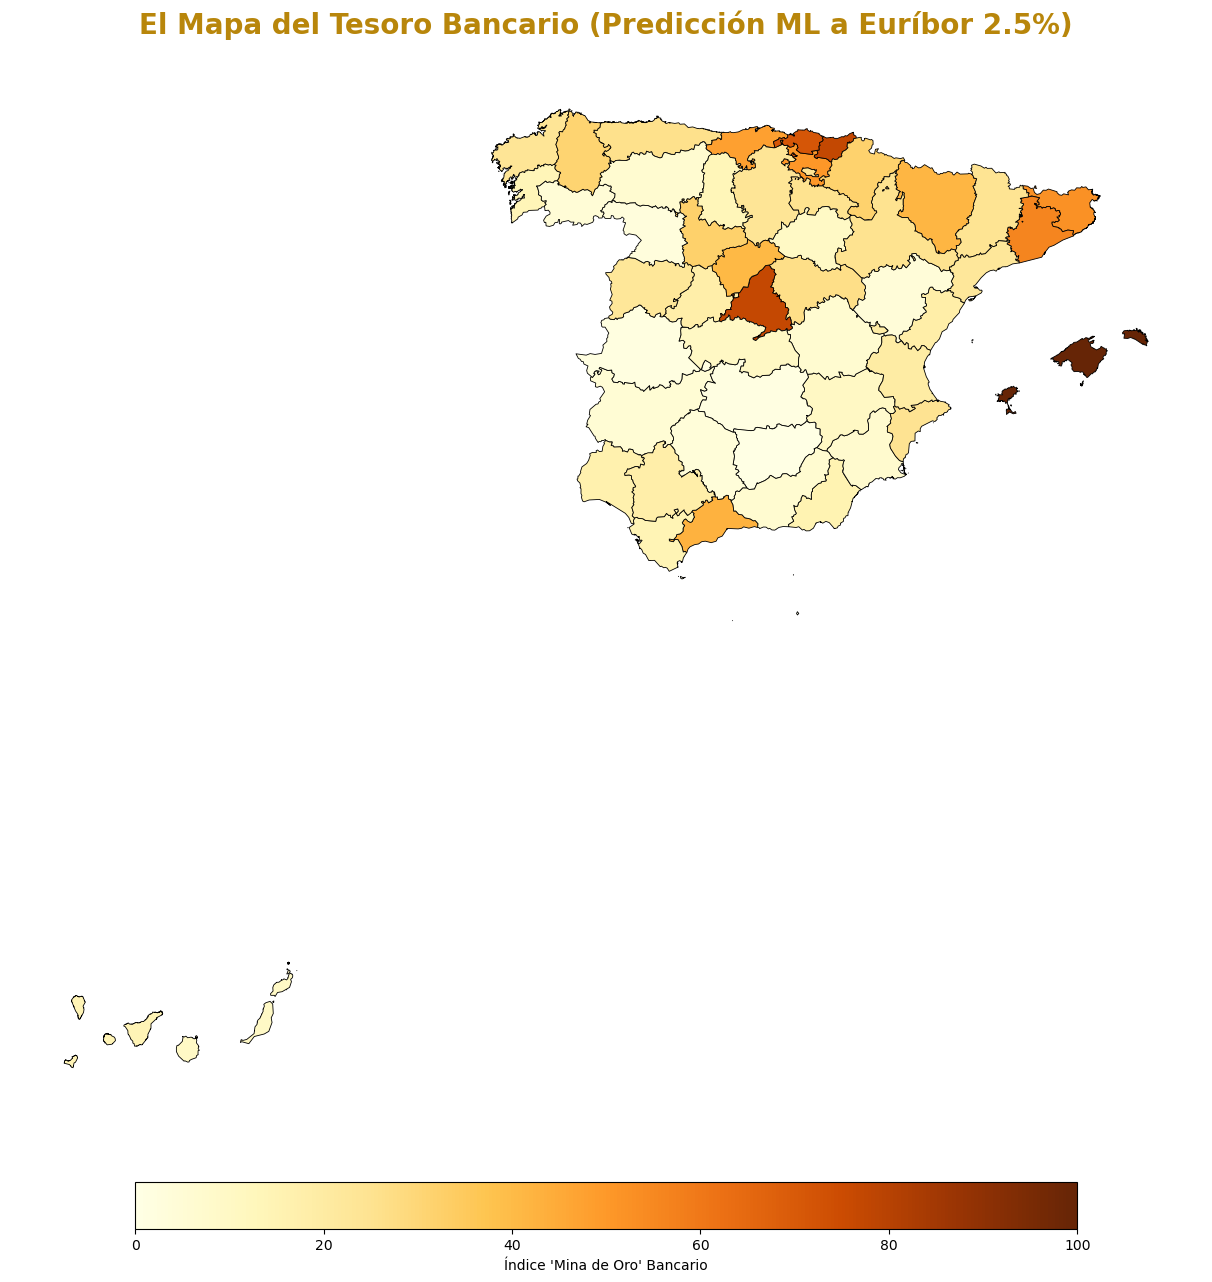

In [ ]:
df_futuro = df[df['Trimestre'] == df['Trimestre'].max()].copy()
df_futuro['Euribor'] = 2.5
df_futuro['Spread_Hipotecas_lag1'] = 1.0
df_futuro['Prediccion_Hipotecas'] = model_stress.predict(df_futuro[feats_stress])

df_futuro['Vol_per_capita'] = df_futuro['Prediccion_Hipotecas'] / df_futuro['Poblacion_lag1']
df_futuro['Score_Bruto'] = (df_futuro['Vol_per_capita'] * df_futuro['Precio_m2_lag1']) / (df_futuro['Tasa_Paro_lag1'] / 100)
min_s = df_futuro['Score_Bruto'].min(); max_s = df_futuro['Score_Bruto'].max()
df_futuro['Mina_Oro_Score'] = 100 * (df_futuro['Score_Bruto'] - min_s) / (max_s - min_s)
df_futuro['Provincia_Clean'] = df_futuro['Provincia'].apply(clean_text_map)
merged3 = gdf.merge(df_futuro, left_on='name_clean', right_on='Provincia_Clean', how='left')

fig, ax = plt.subplots(1, 1, figsize=(16, 14))
ax.set_facecolor('white'); ax.axis('off')
merged3.plot(column='Mina_Oro_Score', cmap='YlOrBr', linewidth=0.6, ax=ax, edgecolor='black',
             legend=True,
             legend_kwds={'label': "Índice 'Mina de Oro' Bancario",
                          'orientation': "horizontal", 'shrink': 0.6, 'pad': 0.05},
             missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})
plt.title("El Mapa del Tesoro Bancario (Predicción ML a Euríbor 2.5%)",
          fontsize=20, fontweight='bold', color='#B8860B', pad=20)
plt.tight_layout(); plt.show()

## 8. Proyección de Variables Macroeconómicas 2026-2030

Proyecciones trimestrales de las variables macro usando el mejor modelo por variable
(seleccionado por backtesting). Euríbor e IPC: proyecciones BCE (exógenas).

In [ ]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Dataset nacional con todos los candidatos
df_sel = df.groupby('Trimestre').agg({
    'Precio_m2':           'mean',
    'Euribor':             'mean',
    'Tasa_Paro':           'mean',
    'PIB_pc':              'mean',
    'IPC':                 'mean',
    'Indice_Materiales':   'mean',
    'Indice_Mano_Obra':    'mean',
    'tasa_ahorro':         'mean',
    'Transmisiones_Total': 'sum',
}).sort_index()

# Crear lags de todos los candidatos
candidatos = ['Euribor','Tasa_Paro','PIB_pc','IPC',
              'Indice_Materiales','Indice_Mano_Obra','tasa_ahorro','Transmisiones_Total']

for col in candidatos:
    df_sel[f'{col}_lag1'] = df_sel[col].shift(1)
    df_sel[f'{col}_lag4'] = df_sel[col].shift(4)

df_sel = df_sel.dropna()
y = np.log(df_sel['Precio_m2'].values)

# Solo usar lags como features (sin contemporáneos → sin leakage)
feature_cols = [f'{c}_lag1' for c in candidatos] + \
               [f'{c}_lag4' for c in candidatos]
X = df_sel[feature_cols].values

# LASSO con CV temporal — penaliza y elimina las variables irrelevantes
scaler = StandardScaler()
X_std  = scaler.fit_transform(X)

lasso = LassoCV(cv=5, max_iter=10000, random_state=42)
lasso.fit(X_std, y)

# Resultado: qué variables sobreviven al LASSO
coefs = pd.Series(lasso.coef_, index=feature_cols).sort_values(key=abs, ascending=False)
print("Variables seleccionadas por LASSO (coef ≠ 0):")
print(coefs[coefs != 0].round(4))
print()
print("Variables eliminadas (coef = 0):")
print(coefs[coefs == 0].index.tolist())

Variables seleccionadas por LASSO (coef ≠ 0):
Euribor_lag4             0.0833
Indice_Mano_Obra_lag4   -0.0322
Euribor_lag1             0.0224
IPC_lag1                 0.0176
Tasa_Paro_lag4          -0.0171
dtype: float64

Variables eliminadas (coef = 0):
['Tasa_Paro_lag1', 'PIB_pc_lag1', 'Indice_Materiales_lag1', 'Indice_Mano_Obra_lag1', 'tasa_ahorro_lag1', 'Transmisiones_Total_lag1', 'PIB_pc_lag4', 'IPC_lag4', 'Indice_Materiales_lag4', 'tasa_ahorro_lag4', 'Transmisiones_Total_lag4']


Horizonte: 2026-01-01 → 2031-10-01  (24 trimestres)

-- PIB_pc -> SARIMA(1,1,0)(1,1,0)4
   OK
-- Tasa_Paro -> ARIMA (Auto AIC)
   Mejor orden: (3, 1, 2)  AIC=172.3
   OK  (suelo 8.5%)
-- Precio_m2 -> Seasonal Naive + tendencia
   OK  (tendencia: 24.81 EUR/m2 por trimestre)
-- tasa_ahorro -> ARIMA (Auto AIC)
   OK  (orden: (3, 1, 2))
-- Transmisiones_Total -> Seasonal Naive + tendencia (excl. Q4 2025)
   OK


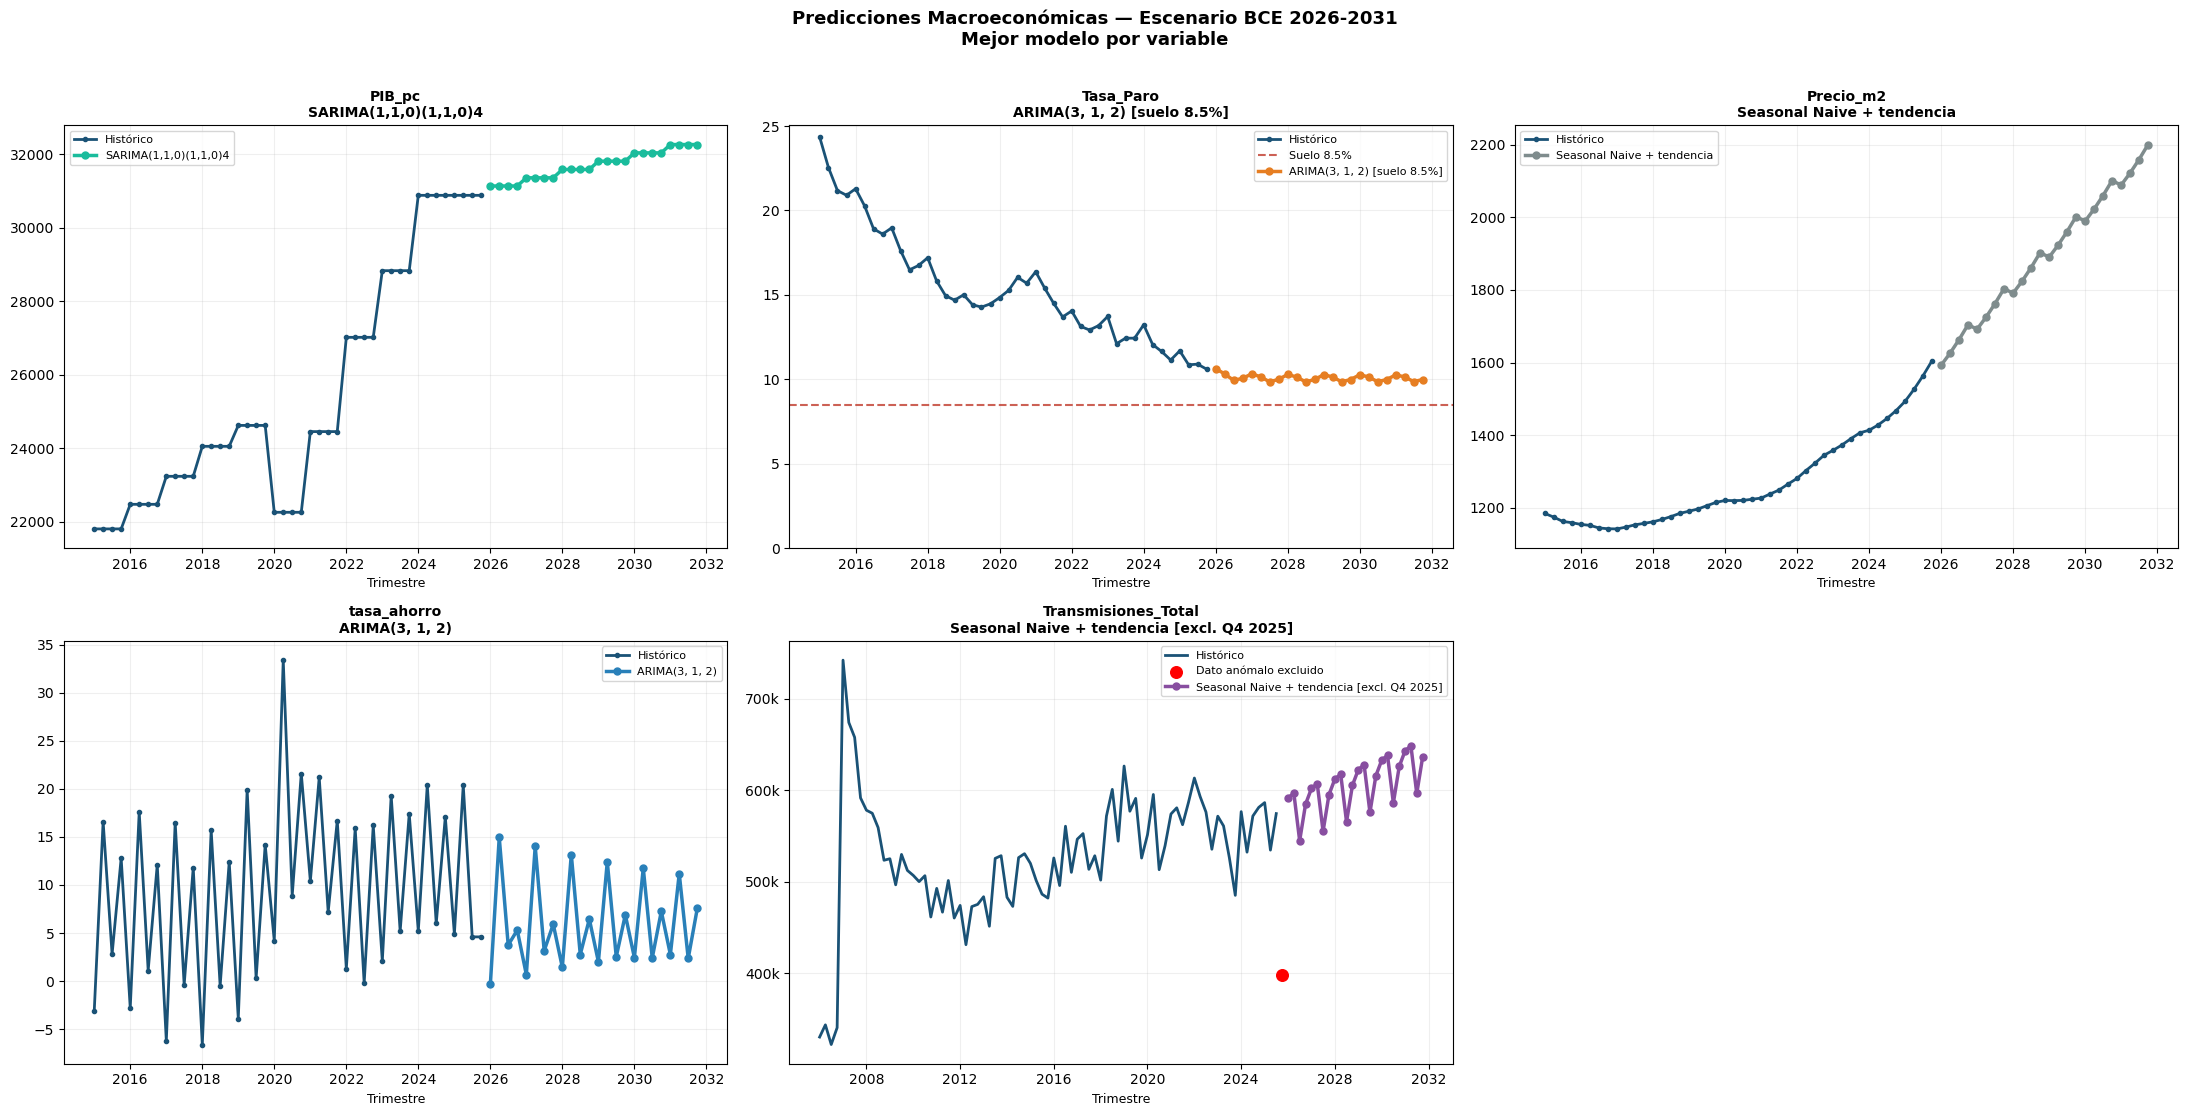


✅ Proyecciones macro listas.


In [ ]:
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

ALL_COLS = ['PIB_pc', 'Tasa_Paro', 'Precio_m2', 'tasa_ahorro', 'Euribor', 'IPC']
TARGETS  = ['PIB_pc', 'Tasa_Paro', 'Precio_m2', 'tasa_ahorro']
PARO_MIN = 8.5

ESCENARIOS_BCE = {
    'Euribor': {'2026': 2.00, '2027': 2.10, '2028': 2.30, '2029': 2.15, '2030': 2.15, '2031': 2.15},
    'IPC':     {'2026': 1.88, '2027': 2.10, '2028': 2.00, '2029': 2.00, '2030': 2.00, '2031': 2.00},
}

def anuales_a_trimestrales(d):
    vals = []
    for anio in sorted(d.keys()):
        vals.extend([d[anio]] * 4)
    return vals

EURIBOR_PROJ = anuales_a_trimestrales(ESCENARIOS_BCE['Euribor'])
IPC_PROJ     = anuales_a_trimestrales(ESCENARIOS_BCE['IPC'])
N_STEPS      = len(EURIBOR_PROJ)

df_q         = _DF_BASE.copy()
df_nac_macro = df_q.groupby('Trimestre')[ALL_COLS].mean().sort_index()
df_nac_macro.index = pd.DatetimeIndex(df_nac_macro.index)
df_full_macro = df_nac_macro.dropna(subset=TARGETS)

last_date  = df_full_macro.index[-1]
future_idx = pd.date_range(start=last_date + pd.DateOffset(months=3), periods=N_STEPS, freq='QS')
print(f"Horizonte: {future_idx[0].date()} → {future_idx[-1].date()}  ({N_STEPS} trimestres)\n")

# Transmisiones
trans_nac_m      = df_q.groupby('Trimestre')['Transmisiones_Total'].sum().sort_index()
trans_nac_m.index = pd.DatetimeIndex(trans_nac_m.index)
tr_trans_m       = trans_nac_m.dropna()
tr_trans_clean_m = tr_trans_m.iloc[:-1]  # excluye Q4 2025 anómalo

# ── PIB_pc — SARIMA(1,1,0)(1,1,0)4 ──────────────────────────────────────────
print("-- PIB_pc -> SARIMA(1,1,0)(1,1,0)4")
tr_pib = pd.Series(df_full_macro['PIB_pc'].values)
try:
    r_pib    = sm.tsa.SARIMAX(tr_pib, order=(1,1,0), seasonal_order=(1,1,0,4)).fit(disp=False)
    fc_pib   = r_pib.get_forecast(steps=N_STEPS)
    pred_pib = fc_pib.predicted_mean.values
    ci_pib   = fc_pib.conf_int()
    lo_pib, hi_pib = ci_pib.iloc[:,0].values, ci_pib.iloc[:,1].values
    print("   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_pib = lo_pib = hi_pib = np.full(N_STEPS, np.nan)

# ── Tasa_Paro — ARIMA Auto AIC + suelo 8.5% ──────────────────────────────────
print("-- Tasa_Paro -> ARIMA (Auto AIC)")
try:
    tr_paro = pd.Series(df_full_macro['Tasa_Paro'].values)
    best_aic, best_order_paro, best_res_paro = np.inf, None, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(tr_paro, order=(p,d,q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_order_paro, best_res_paro = r.aic, (p,d,q), r
                except:
                    pass
    print(f"   Mejor orden: {best_order_paro}  AIC={best_aic:.1f}")
    fc_paro   = best_res_paro.get_forecast(steps=N_STEPS)
    pred_paro = np.clip(fc_paro.predicted_mean.values, PARO_MIN, None)
    ci_paro   = fc_paro.conf_int()
    lo_paro   = np.clip(ci_paro.iloc[:,0].values, PARO_MIN, None)
    hi_paro   = ci_paro.iloc[:,1].values
    print(f"   OK  (suelo {PARO_MIN}%)")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_paro = lo_paro = hi_paro = np.full(N_STEPS, np.nan)
    best_order_paro = "Error"

# ── Precio_m2 — Seasonal Naive + tendencia ───────────────────────────────────
print("-- Precio_m2 -> Seasonal Naive + tendencia")
try:
    tr_pm2    = df_full_macro['Precio_m2'].dropna()
    tendencia = tr_pm2.diff().iloc[-8:].mean()
    base      = np.array([tr_pm2.iloc[-(4 - i % 4)] for i in range(N_STEPS)])
    drift     = np.array([(i // 4 + 1) * 4 * tendencia for i in range(N_STEPS)])
    pred_pm2  = base + drift
    std_qs    = tr_pm2.diff(4).iloc[-16:].std()
    lo_pm2    = pred_pm2 - 1.96 * std_qs
    hi_pm2    = pred_pm2 + 1.96 * std_qs
    print(f"   OK  (tendencia: {tendencia:.2f} EUR/m2 por trimestre)")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_pm2 = lo_pm2 = hi_pm2 = np.full(N_STEPS, np.nan)

# ── tasa_ahorro — ARIMA Auto AIC ─────────────────────────────────────────────
print("-- tasa_ahorro -> ARIMA (Auto AIC)")
try:
    tr_aho = pd.Series(df_full_macro['tasa_ahorro'].values)
    best_aic, best_order_aho, best_res_aho = np.inf, None, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(tr_aho, order=(p,d,q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_order_aho, best_res_aho = r.aic, (p,d,q), r
                except:
                    pass
    fc_aho   = best_res_aho.get_forecast(steps=N_STEPS)
    pred_aho = fc_aho.predicted_mean.values
    ci_aho   = fc_aho.conf_int()
    lo_aho, hi_aho = ci_aho.iloc[:,0].values, ci_aho.iloc[:,1].values
    print(f"   OK  (orden: {best_order_aho})")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_aho = lo_aho = hi_aho = np.full(N_STEPS, np.nan)
    best_order_aho = "Error"

# ── Transmisiones — Seasonal Naive + tendencia (excl. Q4 2025) ───────────────
print("-- Transmisiones_Total -> Seasonal Naive + tendencia (excl. Q4 2025)")
try:
    tendencia_trans = tr_trans_clean_m.diff(4).iloc[-8:].mean()
    base_trans      = np.array([float(tr_trans_clean_m.iloc[-(4 - i % 4)]) for i in range(N_STEPS)])
    drift_trans     = np.array([(i // 4 + 1) * tendencia_trans for i in range(N_STEPS)])
    pred_trans_nac  = base_trans + drift_trans
    std_trans       = tr_trans_clean_m.diff(4).iloc[-16:].std()
    lo_trans        = np.clip(pred_trans_nac - 1.96 * std_trans, 0, None)
    hi_trans        = pred_trans_nac + 1.96 * std_trans
    print("   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_trans_nac = np.full(N_STEPS, float(tr_trans_m.iloc[-5:-1].mean()))
    lo_trans = pred_trans_nac * 0.90
    hi_trans = pred_trans_nac * 1.10

pred_dict = {
    'PIB_pc':              pred_pib,
    'Tasa_Paro':           pred_paro,
    'Precio_m2':           pred_pm2,
    'tasa_ahorro':         pred_aho,
    'Transmisiones_Total': pred_trans_nac
}

modelos_ganadores = {
    'PIB_pc':              'SARIMA(1,1,0)(1,1,0)4',
    'Tasa_Paro':           f'ARIMA{best_order_paro} [suelo {PARO_MIN}%]',
    'Precio_m2':           'Seasonal Naive + tendencia',
    'tasa_ahorro':         f'ARIMA{best_order_aho}',
    'Transmisiones_Total': 'Seasonal Naive + tendencia [excl. Q4 2025]'
}

COLORS_PRED = {
    'PIB_pc':              '#1ABC9C',
    'Tasa_Paro':           '#E67E22',
    'Precio_m2':           '#7F8C8D',
    'tasa_ahorro':         '#2980B9',
    'Transmisiones_Total': '#884EA0'
}

# ── Gráfico ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(22, 11))
fig.suptitle('Predicciones Macroeconómicas — Escenario BCE 2026-2031\nMejor modelo por variable',
             fontsize=13, fontweight='bold', y=1.01)
axes_flat = axes.flatten()

for idx, var in enumerate(list(TARGETS) + ['Transmisiones_Total']):
    ax    = axes_flat[idx]
    color = COLORS_PRED[var]
    preds = pred_dict[var]

    if var == 'Transmisiones_Total':
        ax.plot(tr_trans_clean_m.index, tr_trans_clean_m.values,
                color='#1A5276', linewidth=2, label='Histórico', zorder=3)
        ax.scatter([tr_trans_m.index[-1]], [tr_trans_m.iloc[-1]],
                   color='red', s=70, zorder=6, label='Dato anómalo excluido')
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x/1000)}k'))
    else:
        hist_p = df_full_macro[var].dropna()
        hist_p = hist_p[hist_p.index >= '2015-01-01']
        ax.plot(hist_p.index, hist_p.values, color='#1A5276', linewidth=2,
                marker='o', markersize=3, label='Histórico', zorder=3)
        if var == 'Tasa_Paro':
            ax.set_ylim(bottom=0)
            ax.axhline(y=PARO_MIN, color='#C0392B', linestyle='--', linewidth=1.5,
                       alpha=0.8, label=f'Suelo {PARO_MIN}%')

    ax.plot(future_idx, preds, color=color, linewidth=2.5, marker='o', markersize=5,
            label=modelos_ganadores[var], zorder=5)
    ax.set_title(f'{var}\n{modelos_ganadores[var]}', fontsize=10, fontweight='bold')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc='best')
    ax.set_xlabel('Trimestre', fontsize=9)

axes_flat[5].set_visible(False)
plt.tight_layout()
plt.show()
print("\n✅ Proyecciones macro listas.")

In [ ]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# 1. Definición de métricas
def calc_mape(real, pred):
    r, p = np.array(real, dtype=float), np.array(pred, dtype=float)
    mask = (r != 0) & np.isfinite(r) & np.isfinite(p)
    return float(np.mean(np.abs((r[mask]-p[mask])/r[mask]))*100) if mask.sum()>0 else np.nan

def calc_theils_u2(real, pred, naive_pred):
    r = np.array(real, dtype=float)
    p = np.array(pred, dtype=float)
    n = np.array(naive_pred, dtype=float)
    num = np.sum((r - p) ** 2)
    den = np.sum((r - n) ** 2)
    if den == 0: return np.nan
    return np.sqrt(num / den)

# 2. Configuración del Backtesting (Mismo periodo que la evaluación original)
CUTOFF_TRAIN = '2016-12-31'
CUTOFF_TEST  = '2019-12-31'

df_train = df_full_macro[df_full_macro.index <= CUTOFF_TRAIN]
df_test  = df_full_macro[(df_full_macro.index > CUTOFF_TRAIN) & (df_full_macro.index <= CUTOFF_TEST)]

# Para Transmisiones (que tiene su propio dataframe limpio)
tr_trans_train = tr_trans_clean_m[tr_trans_clean_m.index <= CUTOFF_TRAIN]
tr_trans_test  = tr_trans_clean_m[(tr_trans_clean_m.index > CUTOFF_TRAIN) & (tr_trans_clean_m.index <= CUTOFF_TEST)]

N_STEPS_TEST = len(df_test)
print(f"--- BACKTESTING DE LOS MODELOS GANADORES ---")
print(f"Entrenamiento hasta: {CUTOFF_TRAIN}")
print(f"Periodo de Test: {df_test.index[0].date()} a {df_test.index[-1].date()} ({N_STEPS_TEST} trimestres)\n")

resultados_bt = []

def registrar_metricas(var_name, real, pred, naive_pred, modelo_name):
    mape = calc_mape(real, pred)
    rmse = np.sqrt(mean_squared_error(real, pred))
    mae  = mean_absolute_error(real, pred)
    r2   = r2_score(real, pred)
    u2   = calc_theils_u2(real, pred, naive_pred)
    
    resultados_bt.append({
        'Variable': var_name,
        'Modelo': modelo_name,
        'MAPE (%)': round(mape, 2),
        'RMSE': round(rmse, 2),
        'MAE': round(mae, 2),
        'R2': round(r2, 4),
        'Theils U2': round(u2, 4)
    })

# ── 1. PIB_pc — SARIMA(1,1,0)(1,1,0)4 ──
var = 'PIB_pc'
train_data = pd.Series(df_train[var].values)
test_data = df_test[var].values
naive_pred = np.full(N_STEPS_TEST, train_data.iloc[-1]) # Para Theil's U2

try:
    r_pib = sm.tsa.SARIMAX(train_data, order=(1,1,0), seasonal_order=(1,1,0,4)).fit(disp=False)
    pred_pib = r_pib.get_forecast(steps=N_STEPS_TEST).predicted_mean.values
    registrar_metricas(var, test_data, pred_pib, naive_pred, 'SARIMA(1,1,0)(1,1,0)4')
except Exception as e:
    print(f"Error en {var}: {e}")

# ── 2. Tasa_Paro — ARIMA Auto AIC ──
var = 'Tasa_Paro'
train_data = pd.Series(df_train[var].values)
test_data = df_test[var].values
naive_pred = np.full(N_STEPS_TEST, train_data.iloc[-1])

try:
    best_aic, best_res_paro = np.inf, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(train_data, order=(p,d,q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_res_paro = r.aic, r
                except: pass
    
    fc_paro = best_res_paro.get_forecast(steps=N_STEPS_TEST).predicted_mean.values
    pred_paro = np.clip(fc_paro, PARO_MIN, None)
    registrar_metricas(var, test_data, pred_paro, naive_pred, f'ARIMA (Auto AIC) [Suelo {PARO_MIN}%]')
except Exception as e:
    print(f"Error en {var}: {e}")

# ── 3. Precio_m2 — Seasonal Naive + tendencia ──
var = 'Precio_m2'
train_data = df_train[var]
test_data = df_test[var].values
naive_pred = np.full(N_STEPS_TEST, train_data.iloc[-1])

try:
    tendencia = train_data.diff().iloc[-8:].mean()
    base = np.array([train_data.iloc[-(4 - i % 4)] for i in range(N_STEPS_TEST)])
    drift = np.array([(i // 4 + 1) * 4 * tendencia for i in range(N_STEPS_TEST)])
    pred_pm2 = base + drift
    registrar_metricas(var, test_data, pred_pm2, naive_pred, 'Seasonal Naive + Tendencia')
except Exception as e:
    print(f"Error en {var}: {e}")

# ── 4. tasa_ahorro — ARIMA Auto AIC ──
var = 'tasa_ahorro'
train_data = pd.Series(df_train[var].values)
test_data = df_test[var].values
naive_pred = np.full(N_STEPS_TEST, train_data.iloc[-1])

try:
    best_aic, best_res_aho = np.inf, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(train_data, order=(p,d,q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_res_aho = r.aic, r
                except: pass
    pred_aho = best_res_aho.get_forecast(steps=N_STEPS_TEST).predicted_mean.values
    registrar_metricas(var, test_data, pred_aho, naive_pred, 'ARIMA (Auto AIC)')
except Exception as e:
    print(f"Error en {var}: {e}")

# ── 5. Transmisiones_Total — Seasonal Naive + tendencia ──
var = 'Transmisiones_Total'
train_data = tr_trans_train
test_data = tr_trans_test.values
naive_pred = np.full(N_STEPS_TEST, train_data.iloc[-1])

try:
    tendencia_trans = train_data.diff(4).iloc[-8:].mean()
    base_trans = np.array([float(train_data.iloc[-(4 - i % 4)]) for i in range(N_STEPS_TEST)])
    drift_trans = np.array([(i // 4 + 1) * tendencia_trans for i in range(N_STEPS_TEST)])
    pred_trans = base_trans + drift_trans
    registrar_metricas(var, test_data, pred_trans, naive_pred, 'Seasonal Naive + Tendencia')
except Exception as e:
    print(f"Error en {var}: {e}")

# 3. Mostrar Tabla de Resultados
df_resultados_bt = pd.DataFrame(resultados_bt)
print(df_resultados_bt.to_string(index=False))

--- BACKTESTING DE LOS MODELOS GANADORES ---
Entrenamiento hasta: 2016-12-31
Periodo de Test: 2017-01-01 a 2019-10-01 (12 trimestres)

           Variable                        Modelo  MAPE (%)     RMSE      MAE       R2  Theils U2
             PIB_pc         SARIMA(1,1,0)(1,1,0)4      0.84   215.04   203.41   0.8570     0.1343
          Tasa_Paro ARIMA (Auto AIC) [Suelo 8.5%]      4.64     0.90     0.69   0.6183     0.2912
          Precio_m2    Seasonal Naive + Tendencia      7.09    96.24    84.17 -16.7291     2.4246
        tasa_ahorro              ARIMA (Auto AIC)     97.66     1.67     1.34   0.9684     0.1499
Transmisiones_Total    Seasonal Naive + Tendencia      5.88 39943.06 32833.29  -0.2321     0.6800


In [56]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

print("⏳ Entrenando SARIMA(1,1,0)(1,1,0)4 para PIB_pc y calculando métricas...")

# 1. Cargar datos de forma segura
df_base = pd.read_csv('dataset_final_tfm.csv')
df_base['Trimestre'] = pd.to_datetime(df_base['Trimestre'])
pib = df_base.groupby('Trimestre')['PIB_pc'].mean().sort_index()
pib.index = pd.DatetimeIndex(pib.index, freq='QS')

# 2. División Train/Test (Validación 2017-2019)
CUTOFF_TRAIN = '2016-12-31'
CUTOFF_TEST  = '2019-12-31'

tr_pib = pib[pib.index <= CUTOFF_TRAIN]
te_pib = pib[(pib.index > CUTOFF_TRAIN) & (pib.index <= CUTOFF_TEST)]
N_STEPS = len(te_pib)

# 3. Funciones de métricas
def calc_mape(real, pred):
    r, p = np.array(real, dtype=float), np.array(pred, dtype=float)
    mask = (r != 0) & np.isfinite(r) & np.isfinite(p)
    return float(np.mean(np.abs((r[mask]-p[mask])/r[mask]))*100) if mask.sum()>0 else np.nan

def calc_theils_u2(real, pred, naive_pred):
    r, p, n = np.array(real, float), np.array(pred, float), np.array(naive_pred, float)
    den = np.sum((r - n) ** 2)
    if den == 0: return np.nan
    return np.sqrt(np.sum((r - p) ** 2) / den)

# 4. Entrenar el modelo SARIMA de tu código
try:
    r_pib    = sm.tsa.SARIMAX(tr_pib, order=(1,1,0), seasonal_order=(1,1,0,4)).fit(disp=False)
    fc_pib   = r_pib.get_forecast(steps=N_STEPS)
    pred_pib = fc_pib.predicted_mean.values
    
    # 5. Predicción Naive "Tonta" para Theil's U2
    naive_puro = np.full(N_STEPS, tr_pib.iloc[-1])
    
    # 6. Calcular todas las métricas
    y_real = te_pib.values
    mape_val = calc_mape(y_real, pred_pib)
    rmse_val = np.sqrt(mean_squared_error(y_real, pred_pib))
    mae_val  = mean_absolute_error(y_real, pred_pib)
    r2_val   = r2_score(y_real, pred_pib)
    u2_val   = calc_theils_u2(y_real, pred_pib, naive_puro)
    
    # 7. Mostrar el reporte detallado
    print("\n=== 📈 MÉTRICAS DETALLADAS: SARIMA (PIB_pc) ===")
    print(f"MAPE:       {mape_val:.2f} %")
    print(f"RMSE:       {rmse_val:.2f} €")
    print(f"MAE:        {mae_val:.2f} €")
    print(f"R²:         {r2_val:.4f}")
    print(f"Theil's U2: {u2_val:.4f}")
    print("==============================================\n")
    
except Exception as e:
    print(f"❌ ERROR al entrenar SARIMA: {e}")

⏳ Entrenando SARIMA(1,1,0)(1,1,0)4 para PIB_pc y calculando métricas...

=== 📈 MÉTRICAS DETALLADAS: SARIMA (PIB_pc) ===
MAPE:       0.56 %
RMSE:       146.46 €
MAE:        134.05 €
R²:         0.9337
Theil's U2: 0.0915



Holt-Winters:   MAPE=1.56%
Seasonal Naive: MAPE=1.33%
ARIMA YoY:      MAPE=5.47%
XGBoost:        MAPE=2.67%

=== COMPARATIVA PRECIO M² ===
  Holt-Winters         MAPE=1.56%  Accuracy=98.44%
  Seasonal Naive       MAPE=1.33%  Accuracy=98.67%
  ARIMA YoY            MAPE=5.47%  Accuracy=94.53%
  XGBoost              MAPE=2.67%  Accuracy=97.33%


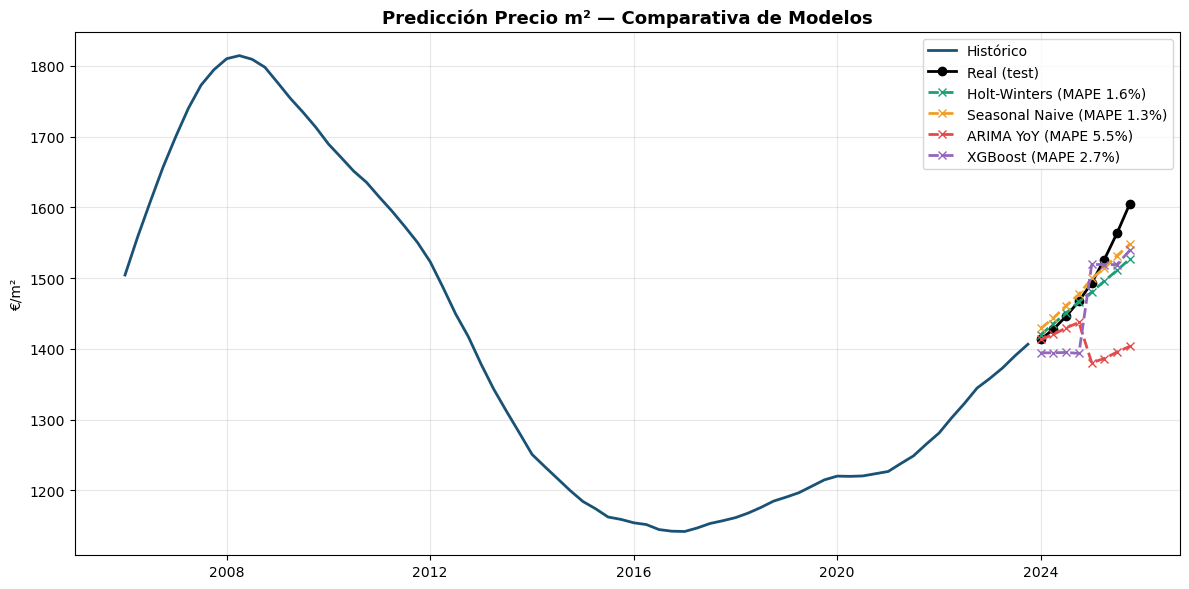

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

precio = df.groupby('Trimestre')['Precio_m2'].mean().sort_index()
precio.index = pd.DatetimeIndex(precio.index, freq='QS')

test_size = 8
tr_precio = precio.iloc[:-test_size]
te_precio = precio.iloc[-test_size:]

# ── Holt-Winters ──────────────────────────────────────────────────
hw      = ExponentialSmoothing(tr_precio, trend='add', seasonal='add',
                               seasonal_periods=4).fit(optimized=True)
pred_hw = hw.forecast(test_size)
mape_hw = mean_absolute_percentage_error(te_precio, pred_hw)
print(f"Holt-Winters:   MAPE={mape_hw*100:.2f}%")

# ── Seasonal Naive + tendencia ────────────────────────────────────
tendencia  = tr_precio.diff().iloc[-8:].mean()
base       = np.array([tr_precio.iloc[-(4 - i % 4)] for i in range(test_size)])
drift      = np.array([(i // 4 + 1) * 4 * tendencia for i in range(test_size)])
pred_naive = pd.Series(base + drift, index=te_precio.index)
mape_naive = mean_absolute_percentage_error(te_precio, pred_naive)
print(f"Seasonal Naive: MAPE={mape_naive*100:.2f}%")

# ── ARIMA sobre variación interanual ─────────────────────────────
precio_yoy = precio - precio.shift(4)
tr_yoy     = precio_yoy.dropna().iloc[:-test_size]
best_aic, best_order, best_res = np.inf, None, None
for p in range(3):
    for q in range(3):
        try:
            r = ARIMA(tr_yoy, order=(p, 0, q)).fit()
            if r.aic < best_aic:
                best_aic, best_order, best_res = r.aic, (p, 0, q), r
        except: continue

fc_yoy     = best_res.get_forecast(steps=test_size)
pred_yoy_v = fc_yoy.predicted_mean.values
last4      = precio.iloc[-test_size-4:-test_size].values
pred_arima_yoy = pd.Series(
    [last4[i % 4] + pred_yoy_v[i] for i in range(test_size)],
    index=te_precio.index)
mape_yoy = mean_absolute_percentage_error(te_precio, pred_arima_yoy)
print(f"ARIMA YoY:      MAPE={mape_yoy*100:.2f}%")

# ── XGBoost multivariante (nacional agregado) ─────────────────────
feats_precio = ['Euribor', 'PIB_pc_lag1', 'Tasa_Paro_lag1',
                'Indice_Materiales_lag1', 'Indice_Mano_Obra_lag1',
                'Precio_m2_lag1']
feats_precio = [f for f in feats_precio if f in df.columns]

precio_nac = df.groupby('Trimestre').agg(
    {f: 'mean' for f in feats_precio + ['Precio_m2']}
).sort_index().dropna()
precio_nac.index = pd.DatetimeIndex(precio_nac.index, freq='QS')

tr_xgb = precio_nac.iloc[:-test_size]
te_xgb = precio_nac.iloc[-test_size:]

xgb_p = xgb.XGBRegressor(n_estimators=300, learning_rate=0.03,
                           max_depth=4, random_state=42, subsample=0.8)
xgb_p.fit(tr_xgb[feats_precio], np.log(tr_xgb['Precio_m2']))

pred_xgb_p = pd.Series(
    np.exp(xgb_p.predict(te_xgb[feats_precio])),
    index=te_xgb.index)
mape_xgb = mean_absolute_percentage_error(te_xgb['Precio_m2'], pred_xgb_p)
print(f"XGBoost:        MAPE={mape_xgb*100:.2f}%")

# ── Resumen ───────────────────────────────────────────────────────
print("\n=== COMPARATIVA PRECIO M² ===")
for nombre, mape in [('Holt-Winters',  mape_hw),
                     ('Seasonal Naive', mape_naive),
                     ('ARIMA YoY',      mape_yoy),
                     ('XGBoost',        mape_xgb)]:
    print(f"  {nombre:20s} MAPE={mape*100:.2f}%  Accuracy={(1-mape)*100:.2f}%")

# ── Gráfico ───────────────────────────────────────────────────────
plt.figure(figsize=(12, 6))
plt.plot(tr_precio.index, tr_precio, color='#1A5276', linewidth=2, label='Histórico')
plt.plot(te_precio.index, te_precio, color='black', linewidth=2,
         marker='o', label='Real (test)')
plt.plot(pred_hw.index,        pred_hw,
         color='#1D9E75', linestyle='--', linewidth=2, marker='x',
         label=f'Holt-Winters (MAPE {mape_hw*100:.1f}%)')
plt.plot(pred_naive.index,     pred_naive,
         color='#EF9F27', linestyle='--', linewidth=2, marker='x',
         label=f'Seasonal Naive (MAPE {mape_naive*100:.1f}%)')
plt.plot(pred_arima_yoy.index, pred_arima_yoy,
         color='#E24B4A', linestyle='--', linewidth=2, marker='x',
         label=f'ARIMA YoY (MAPE {mape_yoy*100:.1f}%)')
plt.plot(pred_xgb_p.index,     pred_xgb_p,
         color='#9467bd', linestyle='--', linewidth=2, marker='x',
         label=f'XGBoost (MAPE {mape_xgb*100:.1f}%)')
plt.title("Predicción Precio m² — Comparativa de Modelos", fontsize=13, fontweight='bold')
plt.ylabel("€/m²")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [54]:
import pandas as pd
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

print("⏳ Entrenando Holt-Winters y calculando métricas...")

# 1. Cargar datos de forma segura desde cero
df_base = pd.read_csv('dataset_final_tfm.csv')
df_base['Trimestre'] = pd.to_datetime(df_base['Trimestre'])
precio = df_base.groupby('Trimestre')['Precio_m2'].mean().sort_index()
precio.index = pd.DatetimeIndex(precio.index, freq='QS')

# 2. División Train/Test (Los 8 trimestres que usaste originalmente)
test_size = 8
tr_precio = precio.iloc[:-test_size]
te_precio = precio.iloc[-test_size:]

# 3. Entrenar el modelo Holt-Winters original
hw = ExponentialSmoothing(tr_precio, trend='add', seasonal='add', seasonal_periods=4).fit(optimized=True)
pred_hw = hw.forecast(test_size)

# 4. Funciones de métricas
def calc_mape(real, pred):
    r, p = np.array(real, dtype=float), np.array(pred, dtype=float)
    mask = (r != 0) & np.isfinite(r) & np.isfinite(p)
    return float(np.mean(np.abs((r[mask]-p[mask])/r[mask]))*100) if mask.sum()>0 else np.nan

def calc_theils_u2(real, pred, naive_pred):
    r, p, n = np.array(real, float), np.array(pred, float), np.array(naive_pred, float)
    den = np.sum((r - n) ** 2)
    if den == 0: return np.nan
    return np.sqrt(np.sum((r - p) ** 2) / den)

# 5. Generar predicción Naive "Tonta" y calcular
naive_puro = np.full(test_size, tr_precio.iloc[-1])

mape_hw = calc_mape(te_precio, pred_hw)
rmse_hw = np.sqrt(mean_squared_error(te_precio, pred_hw))
mae_hw  = mean_absolute_error(te_precio, pred_hw)
r2_hw   = r2_score(te_precio, pred_hw)
u2_hw   = calc_theils_u2(te_precio, pred_hw, naive_puro)

# 6. Mostrar el reporte detallado
print("\n=== 📈 MÉTRICAS DETALLADAS: HOLT-WINTERS ===")
print(f"MAPE:       {mape_hw:.2f} %")
print(f"RMSE:       {rmse_hw:.2f} €/m²")
print(f"MAE:        {mae_hw:.2f} €/m²")
print(f"R²:         {r2_hw:.4f}")
print(f"Theil's U2: {u2_hw:.4f}")
print("=============================================\n")

⏳ Entrenando Holt-Winters y calculando métricas...

=== 📈 MÉTRICAS DETALLADAS: HOLT-WINTERS ===
MAPE:       1.53 %
RMSE:       34.90 €/m²
MAE:        23.81 €/m²
R²:         0.6957
Theil's U2: 0.3261

